# Optimizacija geometrije mehaničkog štita primjenom strojnog učenja
## Diplomski rad

**Autor:** Luka Šebalj 
**Datum:** rujan 2026.

---

### Arhitektura sustava (3 razine)

```
┌──────────────────────────────────────────────────────────────┐
│  RAZINA 1 — DIZAJN                                           │
│  Surogat model (XGBoost + GP) + Pareto optimizacija          │
│  Ulaz: geometrija, materijali, klasa prijetnje               │
│  Izlaz: p_stop, areal_density, cost → Pareto fronta x*       │
└────────────────────┬─────────────────────────────────────────┘
                     │ x* (optimalna konfiguracija)
┌────────────────────▼─────────────────────────────────────────┐
│  RAZINA 2 — UPRAVLJANJE                                      │
│  RecurrentPPO + LSTM agent (Gymnasium env)                   │
│  Ulaz: profil energije udara (time-series, 32 koraka)        │
│  Izlaz: akcija {ne-aktiviraj, aktiviraj_slabo, jako}         │
└────────────────────┬─────────────────────────────────────────┘
                     │ D̂ (stupanj oštećenja 0-3)
┌────────────────────▼─────────────────────────────────────────┐
│  RAZINA 3 — MONITORING                                       │
│  ViT fine-tuning (transfer learning)                         │
│  Ulaz: slike oštećenja post-impact                           │
│  Izlaz: D ∈ {0,1,2,3} → Bayesian update surogata            │
└──────────────────────────────────────────────────────────────┘
```

### Sadržaj
| Tj. | Sadržaj | Notebook |
|-----|---------|----------|
| 1 | Literatura + scope + repo setup |
| 2 | Sintetički dataset + EDA | Sekcija 1–2 |
| 3 | Surogat: XGBoost + GP | Sekcija 3 |
| 4 | Pareto optimizacija | Sekcija 4 |
| 5 | RL okolina + LSTM prediktor | Sekcija 5 |
| 6 | RL trening (RecurrentPPO) | Sekcija 5 |
| 7 | Transfer learning — ViT | Sekcija 6 |
| 8 | Integracija — zatvorena petlja | Sekcija 7 |
| 9 | Validacija + osjetljivost | Sekcija 8 |

## 0. Instalacija i okolina

# Importanje

In [ ]:
# ── SVI IMPORTS ─────────────────────────────────────────────────
import subprocess, sys, os, pickle, json, warnings
from pathlib import Path

# Numerika i vizualizacija
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# PyTorch
import torch
from torch.utils.data import DataLoader
from PIL import Image, ImageDraw

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, confusion_matrix, classification_report
import xgboost as xgb

# Optimizacija
import optuna
from optuna.samplers import NSGAIISampler

# RL
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.callbacks import EvalCallback, BaseCallback
from stable_baselines3.common.monitor import Monitor
try:
    from sb3_contrib import RecurrentPPO
    HAS_SB3_CONTRIB = True
except ImportError:
    from stable_baselines3 import PPO as RecurrentPPO
    HAS_SB3_CONTRIB = False

from tqdm.notebook import tqdm

# HuggingFace
from datasets import load_dataset, Dataset as HFDataset, DatasetDict, Features, Value
from datasets import Image as HFImage
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
)

# Sobol analiza
from SALib.sample import saltelli
from SALib.analyze import sobol

warnings.filterwarnings("ignore")
print("Svi importi učitani")

Svi importi učitani


In [2]:
# Pokrenuti jednom — instalira sve potrebno
# Preporuča se virtualni environment: python -m venv .venv && source .venv/bin/activate

packages = [
    # Core
    "numpy", "pandas", "matplotlib", "seaborn", "plotly",
    # Surrogate & optimization
    "scikit-learn==1.5.*", "xgboost>=2.0", "optuna>=3.6",
    # Deep learning & RL
    "torch", "torchvision",
    "stable-baselines3>=2.3", "sb3-contrib", "gymnasium>=0.29",
    # Transfer learning
    "transformers>=4.42", "datasets>=2.20", "accelerate",
    # Sensitivity analysis
    "SALib>=1.5",
    # Utils
    "tensorboard", "tqdm", "joblib",
]

for pkg in packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

print("Instalacija završena.")

Instalacija završena.


In [3]:
np.random.seed(42)

# Direktoriji projekta
ROOT = Path(".")
DATA_DIR  = ROOT / "data"
MODEL_DIR = ROOT / "models"
REPORT_DIR = ROOT / "reports"
for d in [DATA_DIR, MODEL_DIR, REPORT_DIR, ROOT / "data" / "damage_images"]:
    d.mkdir(parents=True, exist_ok=True)

# ── GPU / CPU detekcija ──────────────────────────────────────────
DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_GPU = DEVICE.type == "cuda"

print(f"NumPy  {np.__version__}")
print(f"Pandas {pd.__version__}")
print(f"PyTorch {torch.__version__}")
print(f"\nUređaj : {DEVICE}")
if USE_GPU:
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("GPU nije dostupan — trening na CPU-u")
    print("  RL trening (~300k koraka): ~20–40 min po prijetnji")
    print("  ViT fine-tuning (15 epoha): može trajati nekoliko sati")

NumPy  2.2.6
Pandas 2.3.3
PyTorch 2.6.0+cu124

Uređaj : cuda
GPU    : NVIDIA GeForce RTX 2080
VRAM   : 8.6 GB


---
## 1. Fizikalni modeli i generiranje sintetičkih podataka

### 1.1 Definicija materijala i klasa prijetnji

Koristimo 6 materijala (4 pasivna + 2 aktivna) i 3 klase prijetnji.

In [ ]:
# ── Materijali ──────────────────────────────────────────────────
MATERIALS = ["B4C", "SiC", "Dyneema", "Kevlar", "NiTi", "MRF132DG", "UHMWPE"]

DENSITY = {          # kg/m³
    "B4C":     2520,
    "SiC":     3210,
    "Dyneema":  970,
    "Kevlar":  1440,
    "NiTi":    6450,
    "MRF132DG":3090,
    "UHMWPE":   955,
}

PRICE = {            # €/kg (srednja vrijednost raspona)
    "B4C":     115,
    "SiC":      55,
    "Dyneema":  90,
    "Kevlar":   45,
    "NiTi":    175,
    "MRF132DG":600,
    "UHMWPE":   28,
}

MATERIAL_TYPE = {
    "B4C": "pasivni", "SiC": "pasivni",
    "Dyneema": "pasivni", "Kevlar": "pasivni",
    "NiTi": "aktivni", "MRF132DG": "aktivni",
    "UHMWPE": "pasivni",
}

# ── Empirijski V50 baza (normiran na AD = 50 kg/m²) ─────────────
V50_BASE = {         # m/s
    "B4C":     850,
    "SiC":     780,
    "Dyneema": 620,
    "Kevlar":  540,
    "NiTi":    480,
    "MRF132DG":510,
    "UHMWPE":  560,
}

# ── Klase prijetnji ─────────────────────────────────────────────
THREAT_CLASSES = {
    "small_arms": {
        "energy_J": (1_000,   5_000),
        "velocity_ms": 800,
        "mass_g_range": (4, 10),
        "prob": 0.50,   
    },
    "fpv_drone": {
        "energy_J": (30_000, 80_000),   
        "velocity_ms": 150,             
        "mass_g_range": (300, 800),     
        "prob": 0.15,
    },
    "at_rocket": {
        "energy_J": (50_000, 200_000),
        "velocity_ms": 300,
        "mass_g_range": (1500, 3000),
        "prob": 0.25,   
    },
    "tank_apfsds": {
        "energy_J": (5_000_000, 10_000_000),
        "velocity_ms": 1700,
        "mass_g_range": (4000, 7000),
        "prob": 0.10,
    },
}

print("Materijali i klase prijetnji definirani.")
pd.DataFrame({
    "Materijal": MATERIALS,
    "Tip": [MATERIAL_TYPE[m] for m in MATERIALS],
    "Gustoća (kg/m³)": [DENSITY[m] for m in MATERIALS],
    "Cijena (€/kg)": [PRICE[m] for m in MATERIALS],
    "V50_baza (m/s)": [V50_BASE[m] for m in MATERIALS],
})

Materijali i klase prijetnji definirani.


,Materijal,Tip,Gustoća (kg/m³),Cijena (€/kg),V50_baza (m/s)
0,B4C,pasivni,2520,115,850
1,SiC,pasivni,3210,55,780
2,Dyneema,pasivni,970,90,620
3,Kevlar,pasivni,1440,45,540
4,NiTi,aktivni,6450,175,480
5,MRF132DG,aktivni,3090,600,510
6,UHMWPE,pasivni,955,28,560


In [5]:
# ── Učitaj već trenirane modele ako postoje ──────────────────────
_THREATS = ["small_arms", "fpv_drone", "at_rocket", "tank_apfsds"]

if (MODEL_DIR / "xgb_surrogates.pkl").exists():
    with open(MODEL_DIR / "xgb_surrogates.pkl", "rb") as f:
        xgb_models = pickle.load(f)
    print("XGBoost učitan")

if (MODEL_DIR / "gp_pstop.pkl").exists():
    with open(MODEL_DIR / "gp_pstop.pkl", "rb") as f:
        gp_bundle = pickle.load(f)
        gp, scaler_gp = gp_bundle["model"], gp_bundle["scaler"]
    print("GP učitan")

rl_models = {}

for threat in _THREATS:
    path = MODEL_DIR / f"ppo_{threat}.zip"
    if path.exists():
        rl_models[threat] = {"model": RecurrentPPO.load(str(path))}
        print(f"RL agent učitan: {threat}")
    else:
        print(f"Error:  RL model nije pronađen: {path}")

# ── ViT ──────────────────────────────────────────────────────────
vit_path = MODEL_DIR / "vit_damage"
config_path = vit_path / "config.json"

vit_ok = False
if config_path.exists():
    with open(config_path) as f:
        cfg = json.load(f)
    vit_ok = "model_type" in cfg

if vit_ok:
    vit_model = AutoModelForImageClassification.from_pretrained(str(vit_path))
    vit_model.to(DEVICE)
    print("ViT učitan")
else:
    print("Error:  ViT nije validan — pokreni trening (cell 37/38)")

XGBoost učitan
GP učitan
RL agent učitan: small_arms
Error:  RL model nije pronađen: models\ppo_fpv_drone.zip
RL agent učitan: at_rocket
RL agent učitan: tank_apfsds
Error:  ViT nije validan — pokreni trening (cell 37/38)


### 1.2 Implementacija fizikalnih modela

- **Lambert-Jonas** V50 model za penetracijsku brzinu
- **Recht-Ipson** rezidualna brzina
- **DOP** (Depth of Penetration) skaliranje za keramiku
- **Areal density** AD = Σ ρᵢ · tᵢ

In [ ]:
def areal_density(layers: list[tuple[str, float]]) -> float:
    #AD = Σ ρ_i * t_i  [kg/m²]
    return sum(DENSITY[m] * t for m, t in layers)

def layer_cost_per_m2(layers: list[tuple[str, float]]) -> float:
    #Trošak po m²  [€/m²
    return sum(DENSITY[m] * t * PRICE[m] for m, t in layers)

def lambert_jonas_v50(
    layers: list[tuple[str, float]],
    ad_ref: float = 50.0,
    ad_exponent: float = 0.45,
) -> float:
    #Težinski usrednjen V50_baza po debljini, skaliran s AD.
    
    total_t = sum(t for _, t in layers)
    if total_t == 0:
        return 0.0
    v50_avg = sum(V50_BASE[m] * t for m, t in layers) / total_t
    ad = areal_density(layers)
    return v50_avg * (ad / ad_ref) ** ad_exponent

def recht_ipson_residual(v_strike: float, v50: float, M: float = 1.0, m_p: float = 0.1) -> float:
    #Rezidualna brzina projektila nakon proboja  [m/s].
    if v_strike <= v50:
        return 0.0
    return (M / (M + m_p)) * np.sqrt(v_strike**2 - v50**2)

def stop_probability(
    v50: float,
    v_strike: float,
    sigma: float = 80.0,
    noise_std: float = 0.04,
) -> float:
    #Logistička p_stop s Gaussovim šumom.
    p = 1.0 / (1.0 + np.exp(-(v50 - v_strike) / sigma))
    return float(np.clip(p + np.random.normal(0, noise_std), 0.0, 1.0))

# ── Provjera ────────────────────────────────────────────────────
test_layers = [("B4C", 0.010), ("Dyneema", 0.015)]
ad  = areal_density(test_layers)
v50 = lambert_jonas_v50(test_layers)
print(f"Test stack: {test_layers}")
print(f"  Areal density : {ad:.1f} kg/m²")
print(f"  V50 efektivni : {v50:.1f} m/s")
print(f"  p_stop (v=800): {stop_probability(v50, 800):.3f}")

Test stack: [('B4C', 0.01), ('Dyneema', 0.015)]
  Areal density : 39.8 kg/m²
  V50 efektivni : 642.2 m/s
  p_stop (v=800): 0.142


### 1.3 Generiranje sintetičkog dataseta (N = 10 000)

In [ ]:
def generate_dataset(n: int = 10_000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    threats = list(THREAT_CLASSES.keys())
    probs   = [THREAT_CLASSES[t]["prob"] for t in threats]

    rows = []
    for _ in range(n):
        # ── Slučajan broj slojeva (1–3) i materijali ────────────
        n_layers = rng.integers(1, 4)
        layers = []
        for _ in range(n_layers):
            mat = rng.choice(MATERIALS)
            t   = rng.uniform(2e-3, 25e-3)  
            layers.append((mat, float(t)))

        # ── Klasa prijetnje ──────────────────────────────────────
        threat = rng.choice(threats, p=probs)
        tc = THREAT_CLASSES[threat]
        E_k = float(rng.uniform(*tc["energy_J"]))
        V_s = float(tc["velocity_ms"])

        # ── Fizikalni izlazi ─────────────────────────────────────
        ad   = areal_density(layers)
        cost = layer_cost_per_m2(layers)
        v50  = lambert_jonas_v50(layers)
        v_res = recht_ipson_residual(V_s, v50)
        p_stop = stop_probability(v50, V_s)

        # ── Enkodiranje layout-a za ML ──────────────────────────
        mat_counts = {m: 0 for m in MATERIALS}
        mat_thickness = {m: 0.0 for m in MATERIALS}
        for m, t in layers:
            mat_counts[m] += 1
            mat_thickness[m] += t

        row = {
            "layout": str(layers),
            "n_layers": n_layers,
            "areal_density": ad,
            "cost_per_m2": cost,
            "threat": threat,
            "E_k": E_k,
            "V_s": V_s,
            "V50_eff": v50,
            "V_residual": v_res,
            "p_stop": p_stop,
        }
        # one-hot prijetnje
        for t in threats:
            row[f"threat_{t}"] = int(threat == t)
        # debljine po materijalu
        for m in MATERIALS:
            row[f"thick_{m}"] = mat_thickness[m]
            row[f"count_{m}"] = mat_counts[m]

        rows.append(row)

    df = pd.DataFrame(rows)
    return df


df = generate_dataset(10_000)
df.to_csv(DATA_DIR / "synthetic_shield.csv", index=False)

print(f"Dataset: {df.shape[0]} redaka × {df.shape[1]} kolona")
print(f"Sprema: {DATA_DIR / 'synthetic_shield.csv'}")
df.describe().round(3)

Dataset: 10000 redaka × 28 kolona
Sprema: data\synthetic_shield.csv


,n_layers,areal_density,cost_per_m2,E_k,V_s,V50_eff,V_residual,p_stop,threat_small_arms,threat_fpv_drone,...,thick_Dyneema,count_Dyneema,thick_Kevlar,count_Kevlar,thick_NiTi,count_NiTi,thick_MRF132DG,count_MRF132DG,thick_UHMWPE,count_UHMWPE
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.0,10000.000,...,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,2.001,72.347,14280.660,778744.757,664.305,675.586,303.347,0.543,0.5,0.151,...,0.004,0.286,0.004,0.284,0.004,0.293,0.004,0.292,0.004,0.278
std,0.809,54.193,15961.090,2267277.319,433.226,257.009,435.664,0.419,0.5,0.358,...,0.008,0.506,0.008,0.504,0.008,0.513,0.008,0.513,0.008,0.498
min,1.000,1.925,53.898,1001.712,150.000,129.312,0.000,0.000,0.0,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,1.000,29.874,2143.549,3073.193,300.000,470.037,0.000,0.054,0.0,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
50%,2.000,60.364,6937.217,30145.281,800.000,676.357,0.000,0.674,0.0,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
75%,3.000,100.849,23229.427,108138.301,800.000,865.944,557.165,0.968,1.0,0.000,...,0.003,1.000,0.003,1.000,0.003,1.000,0.003,1.000,0.003,1.000
max,3.000,436.784,105904.547,9988113.264,1700.000,1507.105,1540.977,1.000,1.0,1.000,...,0.054,3.000,0.051,3.000,0.068,3.000,0.056,3.000,0.055,3.000


---
## 2. Eksploratorna analiza podataka (EDA)

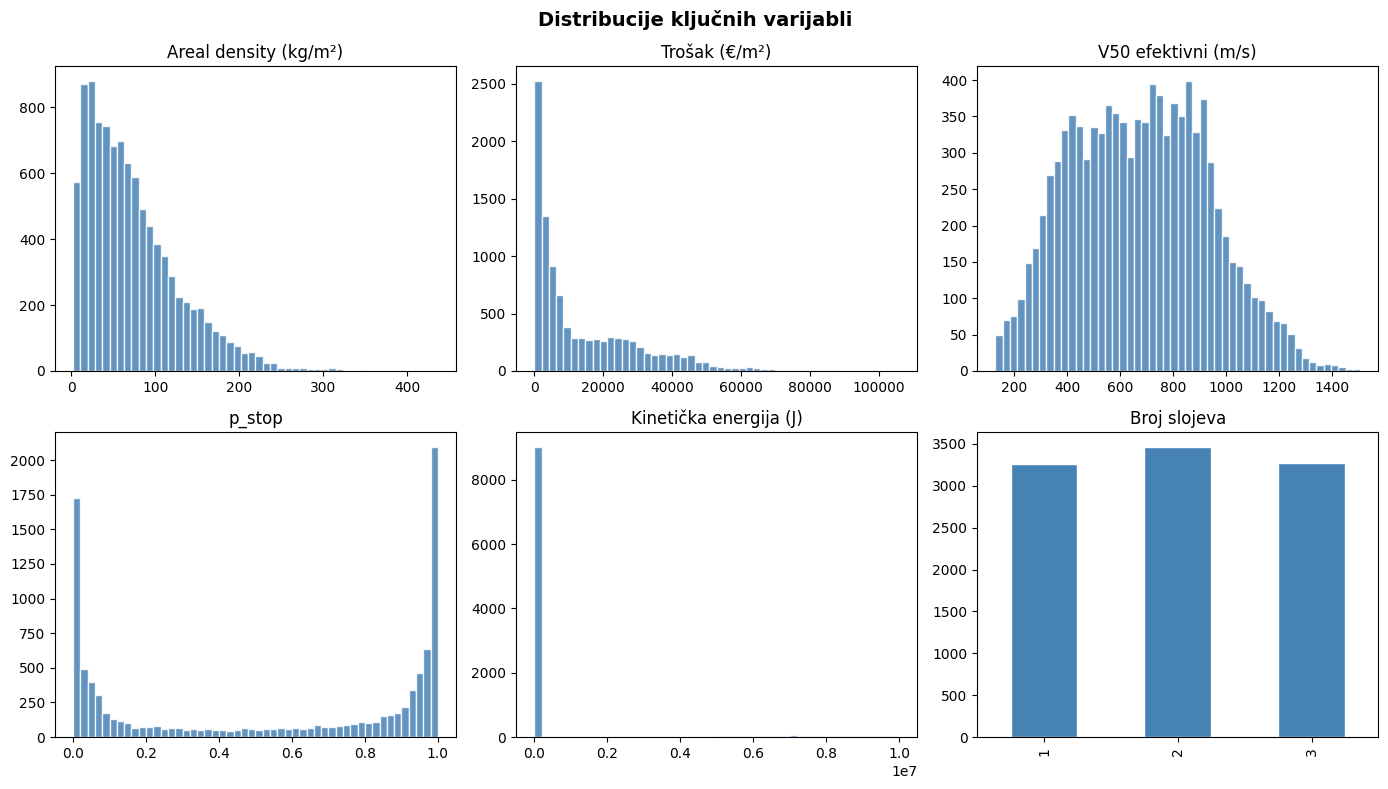

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle("Distribucije ključnih varijabli", fontsize=14, fontweight="bold")

plot_cols = [
    ("areal_density",  "Areal density (kg/m²)"),
    ("cost_per_m2",    "Trošak (€/m²)"),
    ("V50_eff",        "V50 efektivni (m/s)"),
    ("p_stop",         "p_stop"),
    ("E_k",            "Kinetička energija (J)"),
    ("n_layers",       "Broj slojeva"),
]

for ax, (col, label) in zip(axes.flat, plot_cols):
    if col == "n_layers":
        df[col].value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
    else:
        ax.hist(df[col], bins=50, color="steelblue", edgecolor="white", alpha=0.85)
    ax.set_title(label)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(REPORT_DIR / "01_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

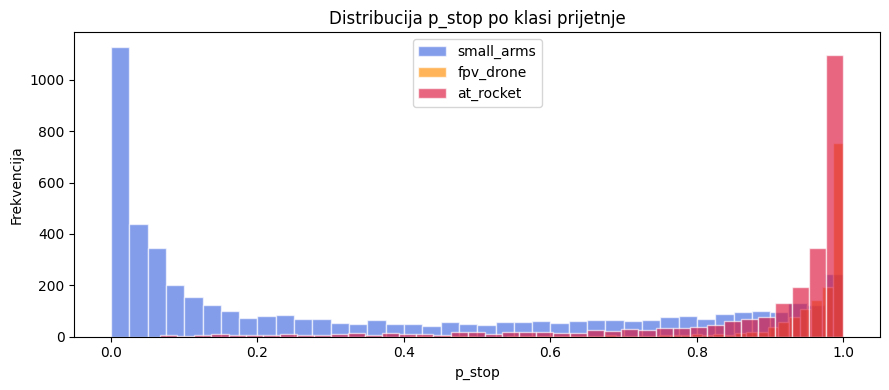

In [9]:
# ── p_stop po klasi prijetnje ────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
for threat, color in zip(THREAT_CLASSES, ["royalblue", "darkorange", "crimson"]):
    data = df[df["threat"] == threat]["p_stop"]
    ax.hist(data, bins=40, alpha=0.65, label=threat, color=color, edgecolor="white")
ax.set_xlabel("p_stop"); ax.set_ylabel("Frekvencija")
ax.set_title("Distribucija p_stop po klasi prijetnje")
ax.legend()
plt.tight_layout()
plt.savefig(REPORT_DIR / "02_pstop_by_threat.png", dpi=120, bbox_inches="tight")
plt.show()

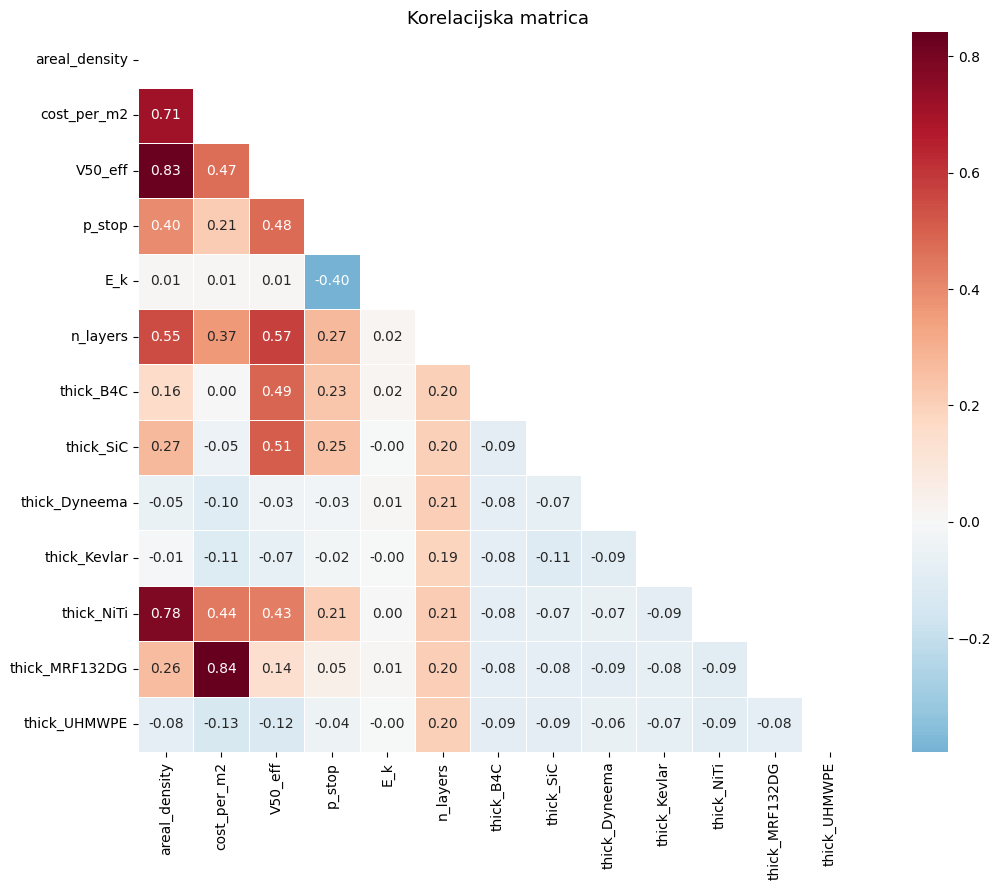

In [10]:
# ── Korelacijska matrica numeričkih varijabli ────────────────────
num_cols = ["areal_density", "cost_per_m2", "V50_eff", "p_stop", "E_k",
            "n_layers"] + [f"thick_{m}" for m in MATERIALS]

corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, square=True, linewidths=0.5, ax=ax
)
ax.set_title("Korelacijska matrica", fontsize=13)
plt.tight_layout()
plt.savefig(REPORT_DIR / "03_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

In [11]:
# ── 3D scatter: AD × cost × p_stop (bojena po prijetnji) ─────────
fig = px.scatter_3d(
    df.sample(2000, random_state=42),
    x="areal_density", y="cost_per_m2", z="p_stop",
    color="threat",
    opacity=0.5, size_max=4,
    title="Prostor rješenja: Areal Density × Trošak × p_stop",
    labels={"areal_density": "AD (kg/m²)", "cost_per_m2": "Trošak (€/m²)"},
)
fig.update_layout(margin=dict(l=0, r=0, b=0, t=40))
fig.show()

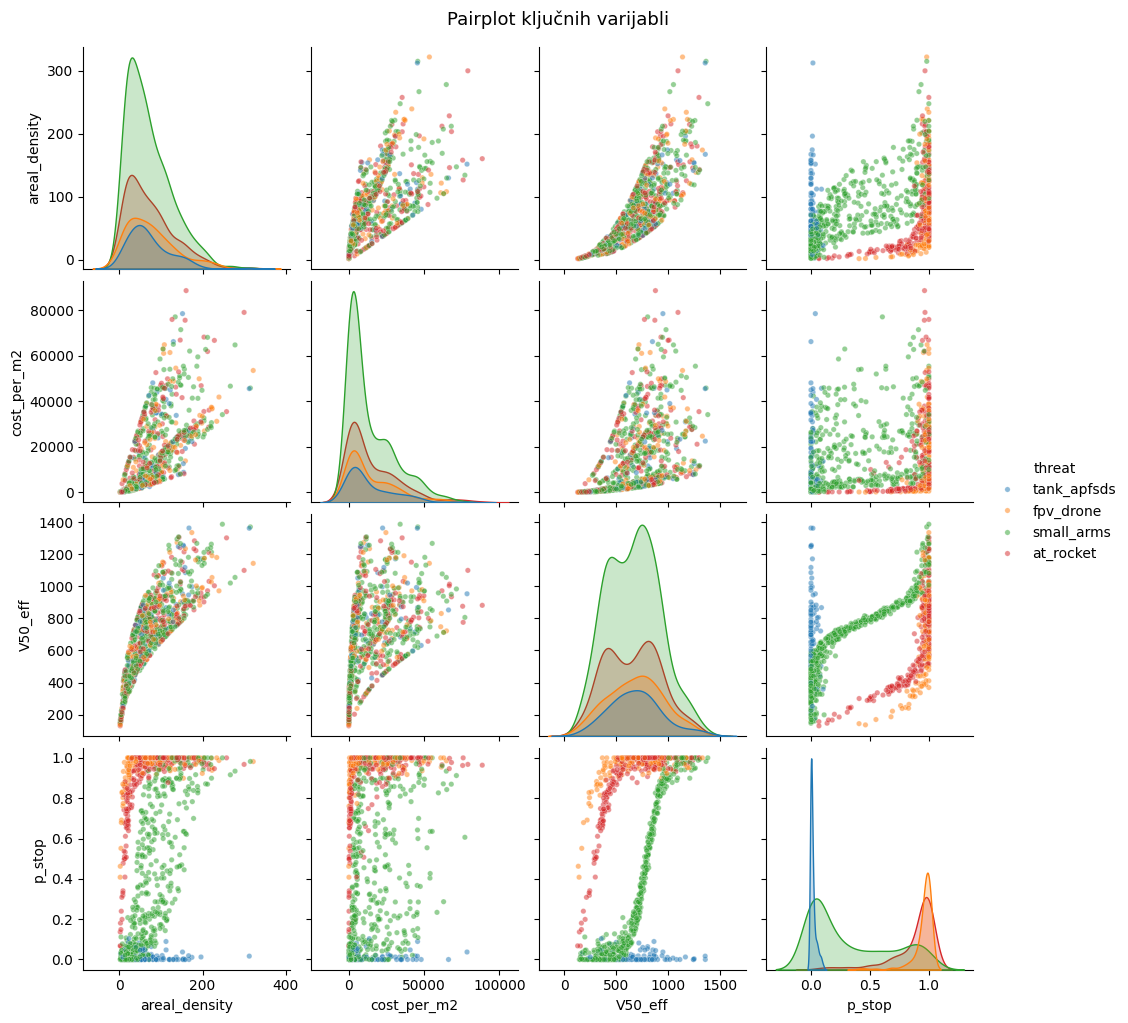

In [12]:
# ── Pairplot ključnih varijabli (uzorak 1000) ────────────────────
pair_df = df[["areal_density", "cost_per_m2", "V50_eff", "p_stop", "threat"]].sample(1000, random_state=42)
g = sns.pairplot(pair_df, hue="threat", diag_kind="kde",
                 plot_kws={"alpha": 0.5, "s": 15})
g.fig.suptitle("Pairplot ključnih varijabli", y=1.02, fontsize=13)
plt.savefig(REPORT_DIR / "04_pairplot.png", dpi=100, bbox_inches="tight")
plt.show()

---
## 3. Razina 1 — DIZAJN: Surogat modeli

**Ciljne varijable:** `p_stop`, `areal_density`, `cost_per_m2`  
**Model 1:** XGBoost (primarni surogat)  
**Model 2:** Gaussian Process (GP) — za kvantifikaciju nesigurnosti

In [13]:
# ── Feature matrica ──────────────────────────────────────────────
FEATURE_COLS = (
    [f"thick_{m}" for m in MATERIALS]
    + [f"count_{m}" for m in MATERIALS]
    + ["n_layers", "areal_density", "E_k"]
    + [f"threat_{t}" for t in THREAT_CLASSES]
)

TARGET_COLS = ["p_stop", "areal_density", "cost_per_m2"]

X = df[FEATURE_COLS].values

# Train / val / test  70 / 15 / 15
X_trainval, X_test, idx_trainval, idx_test = train_test_split(X, df.index, test_size=0.15, random_state=42)
X_train, X_val, ti, vi = train_test_split(X_trainval, idx_trainval, test_size=0.15/0.85, random_state=42)

splits = {"train": ti, "val": vi, "test": idx_test}

print(f"Train: {len(ti):5d}  Val: {len(vi):5d}  Test: {len(idx_test):5d}")

Train:  7000  Val:  1500  Test:  1500


In [14]:
# ── XGBoost surogat ──────────────────────────────────────────────
xgb_models = {}

for target in TARGET_COLS:
    y_train = df.loc[splits["train"], target].values
    y_val   = df.loc[splits["val"],   target].values
    y_test  = df.loc[splits["test"],  target].values

    model = xgb.XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        tree_method="hist",
        eval_metric="rmse",
        early_stopping_rounds=30,
        verbosity=0,
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False,
    )
    xgb_models[target] = model

    y_pred = model.predict(X_test)
    r2  = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    print(f"{target:20s}  R²={r2:.4f}  MAE={mae:.4f}")

# Spremi modele
with open(MODEL_DIR / "xgb_surrogates.pkl", "wb") as f:
    pickle.dump(xgb_models, f)
print("\nModeli spremljeni.")

p_stop                R²=0.9915  MAE=0.0288
areal_density         R²=0.9993  MAE=0.5889
cost_per_m2           R²=0.9993  MAE=220.3637

Modeli spremljeni.


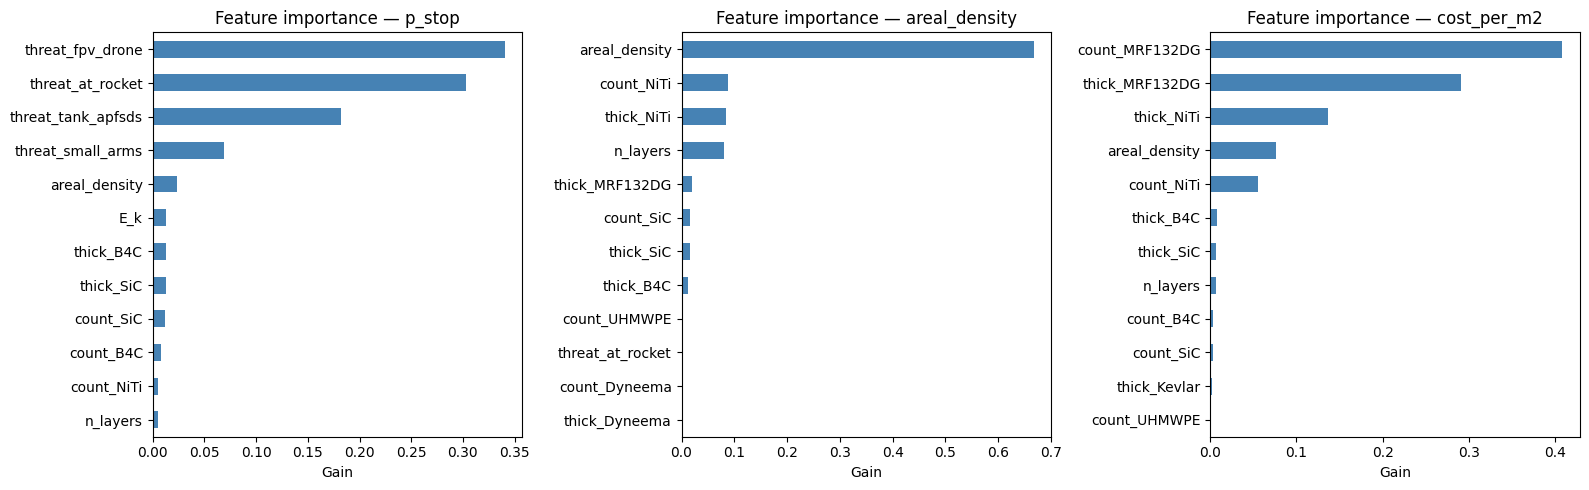

In [15]:
# ── Feature importance (XGBoost) ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, target in zip(axes, TARGET_COLS):
    fi = pd.Series(
        xgb_models[target].feature_importances_,
        index=FEATURE_COLS
    ).sort_values(ascending=False).head(12)
    fi.plot(kind="barh", ax=ax, color="steelblue")
    ax.invert_yaxis()
    ax.set_title(f"Feature importance — {target}")
    ax.set_xlabel("Gain")
plt.tight_layout()
plt.savefig(REPORT_DIR / "05_feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

In [ ]:
# ── Gaussian Process — p_stop s posteriornom nesigurnošću ────────

GP_N_TRAIN = 1500
GP_N_TEST  = 300

idx_train_gp = np.random.choice(list(splits["train"]), GP_N_TRAIN, replace=False)
idx_test_gp  = np.random.choice(list(splits["test"]),  GP_N_TEST,  replace=False)

scaler_gp = StandardScaler()
Xtr_gp = scaler_gp.fit_transform(df.loc[idx_train_gp, FEATURE_COLS].values)
Xte_gp = scaler_gp.transform(df.loc[idx_test_gp, FEATURE_COLS].values)
ytr_gp = df.loc[idx_train_gp, "p_stop"].values
yte_gp = df.loc[idx_test_gp, "p_stop"].values

kernel = ConstantKernel(1.0) * RBF(length_scale=np.ones(Xtr_gp.shape[1])) + WhiteKernel(noise_level=0.01)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=3, normalize_y=True)
gp.fit(Xtr_gp, ytr_gp)

y_pred_gp, y_std_gp = gp.predict(Xte_gp, return_std=True)
print(f"GP  p_stop — R²={r2_score(yte_gp, y_pred_gp):.4f}  MAE={mean_absolute_error(yte_gp, y_pred_gp):.4f}")

with open(MODEL_DIR / "gp_pstop.pkl", "wb") as f:
    pickle.dump({"model": gp, "scaler": scaler_gp}, f)

GP  p_stop — R²=0.9899  MAE=0.0301


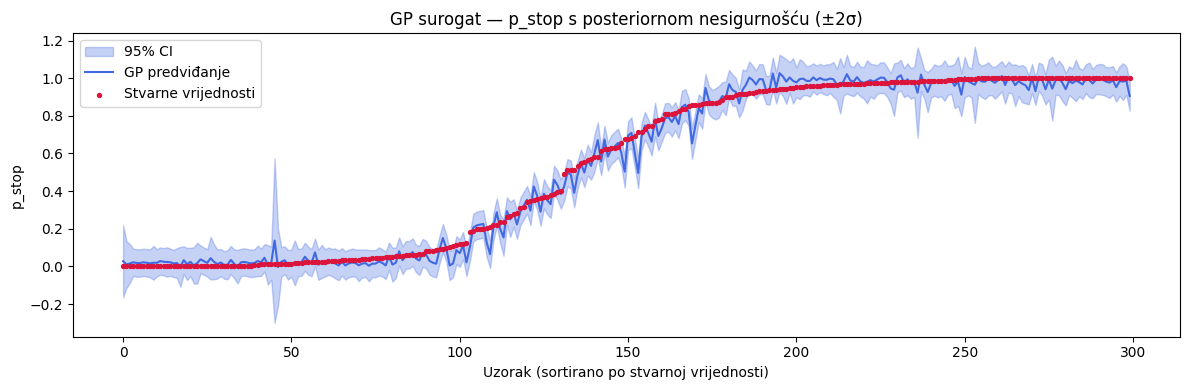

In [17]:
# ── Vizualizacija GP nesigurnosti ────────────────────────────────
sort_idx = np.argsort(yte_gp)
x_plot = np.arange(GP_N_TEST)

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(x_plot,
                y_pred_gp[sort_idx] - 2*y_std_gp[sort_idx],
                y_pred_gp[sort_idx] + 2*y_std_gp[sort_idx],
                alpha=0.3, label="95% CI", color="royalblue")
ax.plot(x_plot, y_pred_gp[sort_idx], label="GP predviđanje", color="royalblue", lw=1.5)
ax.scatter(x_plot, yte_gp[sort_idx], s=8, color="crimson", label="Stvarne vrijednosti", zorder=5)
ax.set_xlabel("Uzorak (sortirano po stvarnoj vrijednosti)")
ax.set_ylabel("p_stop")
ax.set_title("GP surogat — p_stop s posteriornom nesigurnošću (±2σ)")
ax.legend()
plt.tight_layout()
plt.savefig(REPORT_DIR / "06_gp_uncertainty.png", dpi=120, bbox_inches="tight")
plt.show()

# ── Lambert-Jonas: direktna usporedba analitičkog modela i XGBoost surogata ──

Lambert-Jonas (analitički, bez šuma) vs XGBoost surogat:
  R²  = 0.9977
  MAE = 0.0167
  Uzoraka: 500


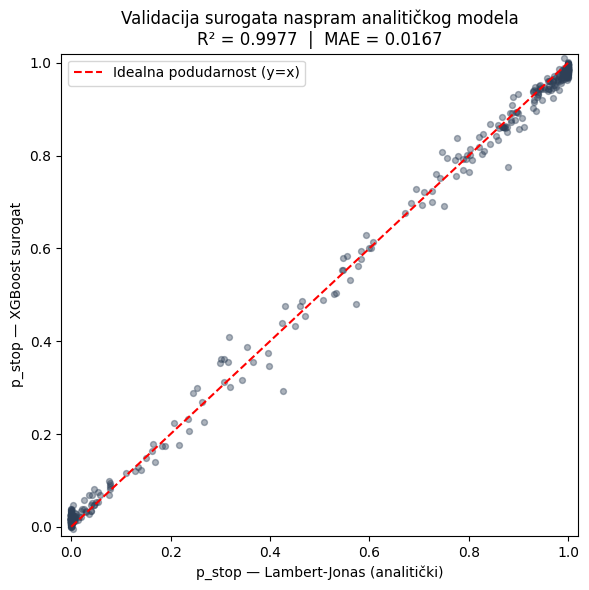


Greška po kategoriji prijetnje:


,mean,max,count
threat,,,
at_rocket,0.0155,0.0940,127
fpv_drone,0.0151,0.1029,113
small_arms,0.0187,0.1342,129
tank_apfsds,0.0173,0.0431,131


In [18]:
# ── Lambert-Jonas: direktna usporedba analitičkog modela i XGBoost surogata ──
def encode_layers(layers, threat):
    thick = {m: 0.0 for m in MATERIALS}
    count = {m: 0 for m in MATERIALS}
    for m, t in layers:
        thick[m] += t
        count[m] += 1
    ad = areal_density(layers)
    e_k = np.mean([THREAT_CLASSES[threat]["energy_J"]])
    row = (
        [thick[m] for m in MATERIALS]
        + [count[m] for m in MATERIALS]
        + [len(layers), ad, e_k]
        + [int(threat == t) for t in THREAT_CLASSES]
    )
    return np.array(row, dtype=np.float32).reshape(1, -1)


rng_val = np.random.default_rng(123)
n_val = 500
analytical_p, surrogate_p, configs_meta = [], [], []
threats_list = list(THREAT_CLASSES.keys())

for _ in range(n_val):
    n_layers = int(rng_val.integers(1, 4))
    layers = []
    for _ in range(n_layers):
        mat = rng_val.choice(MATERIALS)
        t = float(rng_val.uniform(2e-3, 25e-3))
        layers.append((mat, t))

    threat = rng_val.choice(threats_list)
    v_strike = float(THREAT_CLASSES[threat]["velocity_ms"])

    # ── Analitički Lambert-Jonas (BEZ šuma) ──────────────────────
    v50 = lambert_jonas_v50(layers)
    p_analytical = 1.0 / (1.0 + np.exp(-(v50 - v_strike) / 80.0))

    # ── XGBoost surogat ───────────────────────────────────────────
    x = encode_layers(layers, threat)
    p_surrogate = float(xgb_models["p_stop"].predict(x)[0])

    analytical_p.append(p_analytical)
    surrogate_p.append(p_surrogate)
    configs_meta.append({"threat": threat, "n_layers": n_layers})

analytical_p = np.array(analytical_p)
surrogate_p  = np.array(surrogate_p)

r2_val  = r2_score(analytical_p, surrogate_p)
mae_val = mean_absolute_error(analytical_p, surrogate_p)

print(f"Lambert-Jonas (analitički, bez šuma) vs XGBoost surogat:")
print(f"  R²  = {r2_val:.4f}")
print(f"  MAE = {mae_val:.4f}")
print(f"  Uzoraka: {n_val}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(analytical_p, surrogate_p, alpha=0.4, s=18, c="#2E4057")
ax.plot([0, 1], [0, 1], "r--", linewidth=1.5, label="Idealna podudarnost (y=x)")
ax.set_xlabel("p_stop — Lambert-Jonas (analitički)")
ax.set_ylabel("p_stop — XGBoost surogat")
ax.set_title(f"Validacija surogata naspram analitičkog modela\nR² = {r2_val:.4f}  |  MAE = {mae_val:.4f}")
ax.legend()
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
plt.tight_layout()
plt.savefig(REPORT_DIR / "11_lambert_jonas_validation.png", dpi=120, bbox_inches="tight")
plt.show()

val_df = pd.DataFrame(configs_meta)
val_df["p_analytical"] = analytical_p
val_df["p_surrogate"]  = surrogate_p
val_df["abs_error"]    = np.abs(analytical_p - surrogate_p)

print("\nGreška po kategoriji prijetnje:")
display(val_df.groupby("threat")["abs_error"].agg(["mean", "max", "count"]).round(4))

---
## 4. Razina 1 — Pareto optimizacija (Optuna NSGA-II)

**Tri ciljne funkcije:**
1. Maksimizacija `p_stop` (zaštita)
2. Minimizacija `areal_density` (masa)
3. Minimizacija `cost_per_m2` (cijena)

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def encode_layers(layers: list[tuple[str, float]], threat: str) -> np.ndarray:
    #Pretvori listu slojeva u feature vektor za XGBoost surogat.
    thick = {m: 0.0 for m in MATERIALS}
    count = {m: 0   for m in MATERIALS}
    for m, t in layers:
        thick[m] += t
        count[m] += 1

    ad = areal_density(layers)
    e_k = np.mean([THREAT_CLASSES[threat]["energy_J"]])

    row = (
        [thick[m] for m in MATERIALS]
        + [count[m] for m in MATERIALS]
        + [len(layers), ad, e_k]
        + [int(threat == t) for t in THREAT_CLASSES]
    )
    return np.array(row, dtype=np.float32).reshape(1, -1)


def make_objective(threat: str, surrogates: dict):
    def objective(trial: optuna.Trial):
        n_layers = trial.suggest_int("n_layers", 1, 3)
        layers = []
        for i in range(n_layers):
            mat = trial.suggest_categorical(f"mat_{i}", MATERIALS)
            t   = trial.suggest_float(f"t_{i}", 2e-3, 25e-3)
            layers.append((mat, t))

        x = encode_layers(layers, threat)
        p_stop = float(surrogates["p_stop"].predict(x)[0])
        ad     = float(surrogates["areal_density"].predict(x)[0])
        cost   = float(surrogates["cost_per_m2"].predict(x)[0])

        # Optuna: directions=[maximize, minimize, minimize]
        return p_stop, ad, cost

    return objective


pareto_results = {}

for threat in THREAT_CLASSES:
    print(f"Optimizacija za: {threat} ...", end=" ", flush=True)
    study = optuna.create_study(
        directions=["maximize", "minimize", "minimize"],
        sampler=NSGAIISampler(population_size=48, seed=42),
    )
    study.optimize(make_objective(threat, xgb_models), n_trials=600, show_progress_bar=False)
    pareto_results[threat] = study
    n_pareto = len(study.best_trials)
    print(f"{n_pareto} nedominiranih rješenja")

print("\nPareto optimizacija završena.")

Optimizacija za: small_arms ... 164 nedominiranih rješenja
Optimizacija za: fpv_drone ... 141 nedominiranih rješenja
Optimizacija za: at_rocket ... 193 nedominiranih rješenja
Optimizacija za: tank_apfsds ... 72 nedominiranih rješenja

Pareto optimizacija završena.



  TOP-10 konfiguracija — small_arms


,prijetnja,slojevi,n_slojeva,p_stop,masa_kg_m2,cijena_eur
1,small_arms,B4C 10mm + SiC 15mm + NiTi 8mm,3,1.0100,125.32,14701.0
2,small_arms,B4C 20mm + SiC 20mm,2,0.9941,114.92,9317.0
3,small_arms,SiC 20mm + NiTi 20mm,2,0.9852,194.14,26375.0
4,small_arms,SiC 10mm + SiC 15mm + NiTi 8mm,3,0.9823,133.10,13574.0
5,small_arms,B4C 20mm + NiTi 20mm,2,0.9775,180.52,28456.0
6,small_arms,B4C 20mm + SiC 15mm,2,0.9772,99.11,8482.0
7,small_arms,B4C 10mm + SiC 15mm + SiC 8mm,3,0.9767,98.89,6874.0
8,small_arms,SiC 20mm + NiTi 15mm,2,0.9761,159.50,20594.0
9,small_arms,SiC 20mm + SiC 20mm,2,0.9752,129.05,7214.0
10,small_arms,B4C 10mm + B4C 15mm + NiTi 8mm,3,0.9752,114.97,16575.0



  TOP-10 konfiguracija — fpv_drone


,prijetnja,slojevi,n_slojeva,p_stop,masa_kg_m2,cijena_eur
1,fpv_drone,NiTi 20mm + NiTi 20mm,2,1.0217,262.80,45432.0
2,fpv_drone,NiTi 20mm + NiTi 15mm,2,1.0122,223.77,39470.0
3,fpv_drone,NiTi 15mm + NiTi 20mm,2,1.0122,223.77,39470.0
4,fpv_drone,Dyneema 20mm + Dyneema 15mm,2,1.0062,33.95,3110.0
5,fpv_drone,Dyneema 15mm + Dyneema 20mm,2,1.0062,33.95,3110.0
6,fpv_drone,Dyneema 20mm + NiTi 20mm,2,1.0038,148.00,24155.0
7,fpv_drone,B4C 15mm + SiC 10mm,2,1.0036,70.51,6187.0
8,fpv_drone,B4C 15mm + NiTi 5mm,2,1.0035,69.67,9243.0
9,fpv_drone,Dyneema 20mm + NiTi 10mm,2,1.0033,85.02,13385.0
10,fpv_drone,B4C 10mm + SiC 5mm,2,1.0032,42.69,3820.0



  TOP-10 konfiguracija — at_rocket


,prijetnja,slojevi,n_slojeva,p_stop,masa_kg_m2,cijena_eur
1,at_rocket,B4C 8mm + NiTi 8mm + MRF132DG 8mm,3,1.0056,95.32,25519.0
2,at_rocket,B4C 10mm + NiTi 15mm,2,1.0050,122.33,19557.0
3,at_rocket,B4C 10mm + NiTi 10mm + UHMWPE 10mm,3,1.0039,98.86,14554.0
4,at_rocket,B4C 8mm + SiC 8mm + NiTi 8mm,3,1.0014,97.19,13181.0
5,at_rocket,SiC 20mm + SiC 15mm,2,1.0013,112.93,6199.0
6,at_rocket,SiC 15mm + SiC 20mm,2,1.0013,112.93,6199.0
7,at_rocket,B4C 10mm + SiC 15mm,2,1.0011,74.20,5488.0
8,at_rocket,B4C 10mm + B4C 15mm + NiTi 8mm,3,1.0008,114.59,16584.0
9,at_rocket,B4C 15mm + SiC 10mm,2,1.0007,70.56,6200.0
10,at_rocket,B4C 10mm + Dyneema 10mm + NiTi 10mm,3,1.0007,100.46,15216.0



  TOP-10 konfiguracija — tank_apfsds


,prijetnja,slojevi,n_slojeva,p_stop,masa_kg_m2,cijena_eur
1,tank_apfsds,B4C 15mm + SiC 10mm,2,0.0556,70.52,6193.0
2,tank_apfsds,B4C 15mm + NiTi 5mm,2,0.0539,69.71,9238.0
3,tank_apfsds,B4C 8mm + Dyneema 8mm + NiTi 8mm,3,0.0517,79.59,11901.0
4,tank_apfsds,SiC 10mm + NiTi 5mm,2,0.0498,63.58,7683.0
5,tank_apfsds,UHMWPE 10mm + UHMWPE 15mm + UHMWPE 8mm,3,0.0477,31.73,891.0
6,tank_apfsds,B4C 15mm + SiC 8mm + UHMWPE 8mm,3,0.0470,71.16,5952.0
7,tank_apfsds,B4C 8mm + Kevlar 8mm + NiTi 8mm,3,0.0446,82.67,11913.0
8,tank_apfsds,B4C 8mm + SiC 8mm + MRF132DG 8mm,3,0.0441,69.63,19850.0
9,tank_apfsds,UHMWPE 8mm + UHMWPE 8mm + UHMWPE 8mm,3,0.0441,23.56,602.0
10,tank_apfsds,SiC 10mm + Dyneema 10mm + Kevlar 10mm,3,0.0440,56.52,3188.0



Ukupno kombinacija: 3,136
Tablica spremljena → reports\kombinacije_materijala.csv


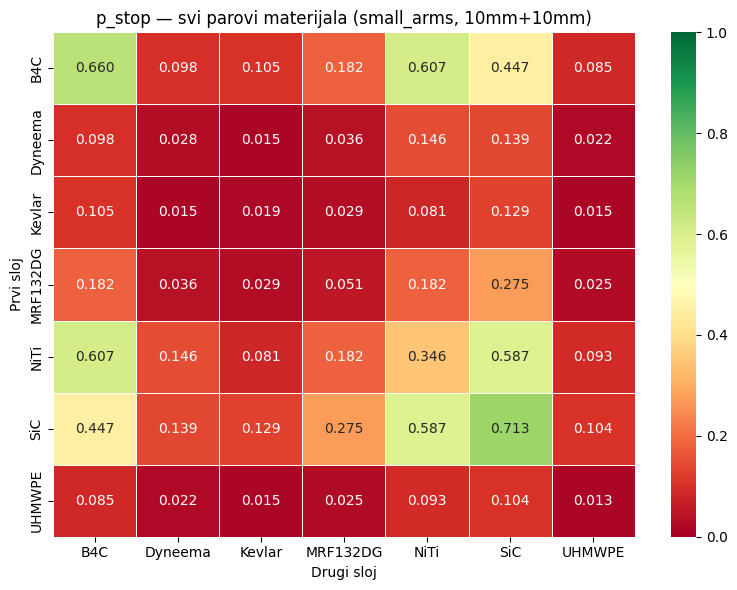

In [20]:
# ── Eksplicitna tablica kombinacija materijala ────────────────────
from itertools import combinations_with_replacement

THICKNESSES = [0.005, 0.010, 0.015, 0.020]  # 5, 10, 15, 20 mm

rows = []

for threat in THREAT_CLASSES:
    tc = THREAT_CLASSES[threat]
    e_k = float(np.mean(tc["energy_J"]))

    # ── Parovi materijala ─────────────────────────────────────────
    for m1, m2 in combinations_with_replacement(MATERIALS, 2):
        for t1 in THICKNESSES:
            for t2 in THICKNESSES:
                layers = [(m1, t1), (m2, t2)]
                x = encode_layers(layers, threat)
                rows.append({
                    "prijetnja":   threat,
                    "slojevi":     f"{m1} {t1*1000:.0f}mm + {m2} {t2*1000:.0f}mm",
                    "n_slojeva":   2,
                    "p_stop":      round(float(xgb_models["p_stop"].predict(x)[0]), 4),
                    "masa_kg_m2":  round(float(xgb_models["areal_density"].predict(x)[0]), 2),
                    "cijena_eur":  round(float(xgb_models["cost_per_m2"].predict(x)[0]), 0),
                })

    # ── Trojke materijala ─────────────────────────────────────────
    for m1, m2, m3 in combinations_with_replacement(MATERIALS, 3):
        for t1, t2, t3 in [(0.008, 0.008, 0.008), (0.010, 0.010, 0.010),
                            (0.015, 0.008, 0.008), (0.010, 0.015, 0.008)]:
            layers = [(m1, t1), (m2, t2), (m3, t3)]
            x = encode_layers(layers, threat)
            rows.append({
                "prijetnja":   threat,
                "slojevi":     f"{m1} {t1*1000:.0f}mm + {m2} {t2*1000:.0f}mm + {m3} {t3*1000:.0f}mm",
                "n_slojeva":   3,
                "p_stop":      round(float(xgb_models["p_stop"].predict(x)[0]), 4),
                "masa_kg_m2":  round(float(xgb_models["areal_density"].predict(x)[0]), 2),
                "cijena_eur":  round(float(xgb_models["cost_per_m2"].predict(x)[0]), 0),
            })

combo_df = pd.DataFrame(rows)

# ── Ispis top-10 po kategoriji prijetnje, sortirano p_stop desc ──
for threat in THREAT_CLASSES:
    print(f"\n{'='*70}")
    print(f"  TOP-10 konfiguracija — {threat}")
    print(f"{'='*70}")
    top = (combo_df[combo_df["prijetnja"] == threat]
           .sort_values("p_stop", ascending=False)
           .head(10)
           .reset_index(drop=True))
    top.index += 1
    display(top)

# ── Spremi cijelu tablicu ─────────────────────────────────────────
combo_df.to_csv(REPORT_DIR / "kombinacije_materijala.csv", index=False)
print(f"\nUkupno kombinacija: {len(combo_df):,}")
print(f"Tablica spremljena → {REPORT_DIR / 'kombinacije_materijala.csv'}")

# ── Heatmapa: p_stop za parove materijala (small_arms, t=10mm) ───
pivot_data = []
for m1 in MATERIALS:
    for m2 in MATERIALS:
        layers = [(m1, 0.010), (m2, 0.010)]
        x = encode_layers(layers, "small_arms")
        pivot_data.append({
            "M1": m1, "M2": m2,
            "p_stop": round(float(xgb_models["p_stop"].predict(x)[0]), 3)
        })

pivot_df = pd.DataFrame(pivot_data).pivot(index="M1", columns="M2", values="p_stop")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pivot_df, annot=True, fmt=".3f", cmap="RdYlGn",
            vmin=0, vmax=1, ax=ax, linewidths=0.5)
ax.set_title("p_stop — svi parovi materijala (small_arms, 10mm+10mm)", fontsize=12)
ax.set_xlabel("Drugi sloj")
ax.set_ylabel("Prvi sloj")
plt.tight_layout()
plt.savefig(REPORT_DIR / "10_heatmapa_kombinacija.png", dpi=120, bbox_inches="tight")
plt.show()

In [21]:
# ── 3D Pareto plotovi (plotly) ───────────────────────────────────
for threat, study in pareto_results.items():
    rows = []
    for trial in study.best_trials:
        p_stop, ad, cost = trial.values
        rows.append({"p_stop": p_stop, "areal_density": ad, "cost_per_m2": cost})
    pf = pd.DataFrame(rows)

    fig = go.Figure(data=[
        go.Scatter3d(
            x=pf["areal_density"], y=pf["cost_per_m2"], z=pf["p_stop"],
            mode="markers",
            marker=dict(size=5, color=pf["p_stop"], colorscale="Viridis",
                        showscale=True, colorbar=dict(title="p_stop")),
            text=[f"p={r['p_stop']:.2f} AD={r['areal_density']:.1f} €={r['cost_per_m2']:.0f}"
                  for _, r in pf.iterrows()],
        )
    ])
    fig.update_layout(
        title=f"Pareto fronta — {threat}",
        scene=dict(
            xaxis_title="Areal density (kg/m²)",
            yaxis_title="Trošak (€/m²)",
            zaxis_title="p_stop",
        ),
        margin=dict(l=0, r=0, b=0, t=40),
    )
    fig.show()

In [ ]:
# ── Top-10 konfiguracija po klasi (sortiranje po p_stop desc) ────
for threat, study in pareto_results.items():
    rows = []
    for trial in study.best_trials:
        p_stop, ad, cost = trial.values
        n = trial.params.get("n_layers", 1)
        layout = ", ".join(
            f"{trial.params[f'mat_{i}']} {trial.params[f't_{i}']*1000:.1f}mm"
            for i in range(n)
        )
        rows.append({"layout": layout, "p_stop": round(p_stop, 3),
                     "AD (kg/m²)": round(ad, 1), "Trošak (€/m²)": round(cost, 0)})

    top10 = pd.DataFrame(rows).sort_values("p_stop", ascending=False).head(10)
    print(f"\n=== Top-10 konfiguracija — {threat} ===")
    display(top10.reset_index(drop=True))


=== Top-10 konfiguracija — small_arms ===


,layout,p_stop,AD (kg/m²),Trošak (€/m²)
0,"B4C 18.5mm, MRF132DG 21.9mm, SiC 13.9mm",1.014,157.6,47038.0
1,"B4C 8.7mm, B4C 20.5mm, NiTi 19.0mm",1.004,198.4,29520.0
2,"Dyneema 7.6mm, B4C 24.5mm, NiTi 15.5mm",0.998,169.4,25006.0
3,"B4C 23.4mm, NiTi 14.1mm, Dyneema 9.3mm",0.995,160.2,23523.0
4,"SiC 23.4mm, B4C 16.3mm",0.994,114.8,8861.0
5,"SiC 13.5mm, B4C 24.9mm",0.990,105.1,9456.0
6,"SiC 20.8mm, B4C 17.9mm",0.977,113.3,8974.0
7,"SiC 23.4mm, SiC 18.1mm",0.976,133.6,7403.0
8,"SiC 12.6mm, B4C 23.4mm",0.974,99.0,8917.0
9,"SiC 18.6mm, SiC 18.5mm",0.964,118.1,6656.0



=== Top-10 konfiguracija — fpv_drone ===


,layout,p_stop,AD (kg/m²),Trošak (€/m²)
0,"Dyneema 16.6mm, Dyneema 17.6mm, MRF132DG 23.5mm",1.029,105.4,46018.0
1,"Dyneema 15.4mm, Dyneema 19.1mm",1.012,33.7,2975.0
2,SiC 12.8mm,0.997,40.6,2245.0
3,SiC 12.8mm,0.997,40.6,2245.0
4,SiC 7.6mm,0.992,24.2,1376.0
5,SiC 7.6mm,0.992,24.2,1376.0
6,SiC 7.0mm,0.987,22.2,1240.0
7,SiC 7.0mm,0.987,22.2,1240.0
8,"SiC 3.9mm, UHMWPE 19.0mm",0.982,30.7,1207.0
9,SiC 6.7mm,0.979,21.5,1239.0



=== Top-10 konfiguracija — at_rocket ===


,layout,p_stop,AD (kg/m²),Trošak (€/m²)
0,"Dyneema 16.6mm, Dyneema 17.6mm, MRF132DG 23.5mm",1.005,105.4,45929.0
1,"B4C 14.6mm, NiTi 11.3mm",0.998,109.6,17036.0
2,SiC 24.2mm,0.998,77.4,4213.0
3,SiC 24.2mm,0.998,77.4,4213.0
4,"B4C 6.1mm, SiC 12.2mm, MRF132DG 17.1mm",0.998,107.9,36006.0
5,SiC 24.2mm,0.998,77.4,4213.0
6,SiC 24.2mm,0.998,77.4,4213.0
7,SiC 24.2mm,0.998,77.4,4213.0
8,SiC 23.4mm,0.996,75.1,4162.0
9,SiC 23.8mm,0.996,76.3,4192.0



=== Top-10 konfiguracija — tank_apfsds ===


,layout,p_stop,AD (kg/m²),Trošak (€/m²)
0,"SiC 7.7mm, B4C 13.2mm",0.053,58.1,5504.0
1,"B4C 6.0mm, SiC 12.8mm, UHMWPE 19.7mm",0.049,74.0,4633.0
2,"Dyneema 24.7mm, B4C 13.2mm",0.048,58.1,6182.0
3,"B4C 12.3mm, NiTi 3.0mm",0.045,50.6,6462.0
4,"UHMWPE 14.4mm, UHMWPE 20.5mm, B4C 14.0mm",0.043,68.4,5089.0
5,"B4C 6.0mm, SiC 13.3mm",0.043,56.8,4104.0
6,"B4C 14.4mm, UHMWPE 21.0mm",0.042,55.8,4846.0
7,"SiC 7.7mm, UHMWPE 10.0mm, UHMWPE 23.3mm",0.040,57.0,2163.0
8,"UHMWPE 15.6mm, SiC 4.2mm, SiC 4.7mm",0.039,44.3,2030.0
9,"Dyneema 5.7mm, Kevlar 21.0mm",0.036,36.1,1888.0


---
## 5. Razina 2 — UPRAVLJANJE: RL agent s LSTM (RecurrentPPO)

**Okolina:** ShieldEnv (Gymnasium)  
**Agent:** RecurrentPPO (sb3-contrib) s MlpLstmPolicy  
**Akcijski prostor:** {0=ne-aktiviraj, 1=aktiviraj_slabo, 2=aktiviraj_jako}

In [ ]:
class ShieldEnv(gym.Env):
    #Pojednostavljena RL okolina za upravljanje aktivacijom pametnog sloja.

    metadata = {"render_modes": []}

    # Reward koeficijenti
    ALPHA = 1.0   # rezidualni integritet
    BETA  = 0.02  # trošak aktivacije
    GAMMA = 0.5   # penalizacija proboja

    # Kritična energija po klasi (J) — ispod koje štit drži
    E_CRITICAL = {
    "small_arms":  500,
    "fpv_drone":   8_000,   
    "at_rocket":   5_000,
    "tank_apfsds": 500_000,
    }

    def __init__(self, threat: str = "small_arms", max_steps: int = 30):
        super().__init__()
        self.threat = threat
        self.max_steps = max_steps

        # Stanje: [E_norm, t_norm, activation, integrity, 5× history]
        self.observation_space = spaces.Box(-1.0, 1.0, shape=(8,), dtype=np.float32)
        self.action_space = spaces.Discrete(3)  # 0, 1, 2

        self._E_init = float(np.mean(THREAT_CLASSES[threat]["energy_J"]))
        self._E_crit = self.E_CRITICAL[threat]

    def _obs(self) -> np.ndarray:
        e_norm = np.clip(self.E / self._E_init, 0, 1)
        t_norm = self.t / self.max_steps
        integ  = self.integrity
        act    = self.activation / 2.0
        # ostatak popunjava history buffer
        obs = np.array(
            [e_norm, t_norm, act, integ] + list(self._hist[-4:]),
            dtype=np.float32
        )
        return obs

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        tc = THREAT_CLASSES[self.threat]
        self.E = float(self.np_random.uniform(*tc["energy_J"]))
        self.t = 0
        self.activation = 0
        self.integrity = 1.0
        self._hist = [0.0] * 4
        return self._obs(), {}

    def step(self, action: int):
        action = int(action)  
        act_cost = [0.0, 1.0, 3.0][action]
        self.activation = action

        decay = 0.05 + 0.06 * action
        self.E = float(self.E * (1.0 - decay))   
        self.t += 1

        margin = (self._E_crit - self.E) / self._E_crit
        breach_prob = 1.0 / (1.0 + np.exp(4 * margin))
        breach = bool(self.np_random.random() < breach_prob)  

        if breach:
            dmg = 0.30 * (1.0 - 0.25 * action)
            self.integrity = float(max(0.0, self.integrity - dmg))  

        done = bool(
            (self.E < 1e-3) or (self.t >= self.max_steps) or (self.integrity <= 0)
        )  

        reward = float(
            self.ALPHA * self.integrity
            - self.BETA * act_cost
            - self.GAMMA * float(breach)
        )

        self._hist.pop(0)
        self._hist.append(float(self.E / self._E_init))

        return self._obs(), reward, done, False, {"breach": breach, "E": self.E}

# ── Brza provjera okoline ────────────────────────────────────────
env = ShieldEnv(threat="small_arms")
obs, _ = env.reset(seed=0)
for _ in range(5):
    a = env.action_space.sample()
    obs, r, done, _, info = env.step(a)
    print(f"  akcija={a}  reward={r:.3f}  E={info['E']:.1f}  breach={info['breach']}")
print("Okolina OK")

  akcija=2  reward=0.290  E=2944.7  breach=True
  akcija=1  reward=0.105  E=2620.8  breach=True
  akcija=1  reward=-0.120  E=2332.5  breach=True
  akcija=0  reward=-0.400  E=2215.9  breach=True
  akcija=1  reward=-0.520  E=1972.1  breach=True
Okolina OK


In [24]:
# ── Provjera sb3 API-ja ──────────────────────────────────────────
check_env(ShieldEnv("small_arms"), warn=True)
print("Gymnasium env provjera prošla.")

Gymnasium env provjera prošla.


In [25]:
class RewardLogger(BaseCallback):
    def __init__(self, total_steps):
        super().__init__()
        self.episode_rewards = []
        self.pbar = tqdm(total=total_steps, unit="korak", leave=True)
        self._last_step = 0

    def _on_step(self):
        self.pbar.update(self.num_timesteps - self._last_step)
        self._last_step = self.num_timesteps

        if self.locals.get("dones", [False])[0]:
            info = self.locals["infos"][0]
            ep = info.get("episode", {})
            if ep:
                self.episode_rewards.append(ep["r"])
                avg = np.mean(self.episode_rewards[-50:])
                self.pbar.set_postfix({"avg_reward": f"{avg:.3f}", "epizode": len(self.episode_rewards)})
        return True

    def _on_training_end(self):
        self.pbar.close()

rl_models = {}

TOTAL_TIMESTEPS = {
    "small_arms":  1_000_000,
    "fpv_drone":   1_000_000,
    "at_rocket":   1_000_000,
    "tank_apfsds": 1_500_000,
}

policy_name = "MlpLstmPolicy" if HAS_SB3_CONTRIB else "MlpPolicy"
print(f"Uređaj: {DEVICE}  |  Politika: {policy_name}")
print(f"Timesteps: {TOTAL_TIMESTEPS}\n")

for threat in THREAT_CLASSES:
    steps = TOTAL_TIMESTEPS[threat]
    print(f"\n── Trening: '{threat}' ({steps:,} koraka) ──")
    train_env = Monitor(ShieldEnv(threat=threat))
    cb = RewardLogger(total_steps=steps)

    model = RecurrentPPO(
        policy_name, train_env,
        learning_rate=3e-4,
        n_steps=256,
        batch_size=64,
        n_epochs=4,
        gamma=0.99,
        verbose=0,
        device=DEVICE,
        ent_coef=0.01,
        tensorboard_log=str(ROOT / "tensorboard" / threat),
    )
    model.learn(total_timesteps=steps, callback=cb)
    model.save(str(MODEL_DIR / f"ppo_{threat}"))
    rl_models[threat] = {"model": model, "rewards": cb.episode_rewards}
    mean_last = np.mean(cb.episode_rewards[-50:]) if cb.episode_rewards else float("nan")
    print(f"✅ Završeno. Avg reward (zadnjih 50): {mean_last:.3f}")

print("\n RL trening završen.")

Uređaj: cuda  |  Politika: MlpLstmPolicy
Timesteps: {'small_arms': 1000000, 'fpv_drone': 1000000, 'at_rocket': 1000000, 'tank_apfsds': 1500000}


── Trening: 'small_arms' (1,000,000 koraka) ──


  0%|          | 0/1000000 [00:00<?, ?korak/s]

✅ Završeno. Avg reward (zadnjih 50): -0.434

── Trening: 'fpv_drone' (1,000,000 koraka) ──


  0%|          | 0/1000000 [00:00<?, ?korak/s]

✅ Završeno. Avg reward (zadnjih 50): -0.410

── Trening: 'at_rocket' (1,000,000 koraka) ──


  0%|          | 0/1000000 [00:00<?, ?korak/s]

✅ Završeno. Avg reward (zadnjih 50): -0.330

── Trening: 'tank_apfsds' (1,500,000 koraka) ──


  0%|          | 0/1500000 [00:00<?, ?korak/s]

✅ Završeno. Avg reward (zadnjih 50): -0.410

 RL trening završen.


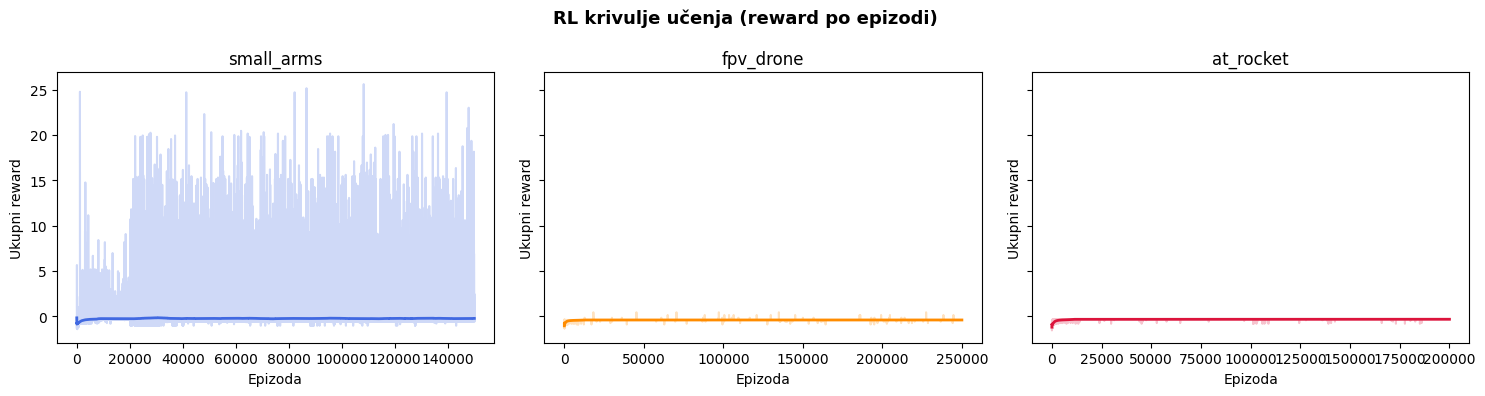

In [26]:
# ── Krivulje učenja ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
fig.suptitle("RL krivulje učenja (reward po epizodi)", fontsize=13, fontweight="bold")

colors = ["royalblue", "darkorange", "crimson"]
for ax, (threat, data), color in zip(axes, rl_models.items(), colors):
    rewards = data["rewards"]
    window = max(1, len(rewards)//20)
    smooth = pd.Series(rewards).rolling(window, min_periods=1).mean()
    ax.plot(rewards, alpha=0.25, color=color)
    ax.plot(smooth, color=color, lw=2)
    ax.set_title(threat)
    ax.set_xlabel("Epizoda")
    ax.set_ylabel("Ukupni reward")

plt.tight_layout()
plt.savefig(REPORT_DIR / "07_rl_learning_curves.png", dpi=120, bbox_inches="tight")
plt.show()

In [27]:
# ── Ablation study: bez aktivacije / random / RL ─────────────────
def evaluate_policy(env_fn, policy_fn, n_episodes: int = 100) -> dict:
    total_rewards, breaches, survivals = [], [], []
    for _ in range(n_episodes):
        env = env_fn()
        obs, _ = env.reset()
        done = False
        ep_r = 0.0
        ep_breach = 0
        lstm_state = None
        while not done:
            action, lstm_state = policy_fn(obs, lstm_state)
            obs, r, done, _, info = env.step(action)
            ep_r += r
            ep_breach += int(info["breach"])
        total_rewards.append(ep_r)
        breaches.append(ep_breach)
        survivals.append(env.integrity)
    return {
        "mean_reward": np.mean(total_rewards),
        "mean_breaches": np.mean(breaches),
        "mean_integrity": np.mean(survivals),
    }


ablation_rows = []
threat = "small_arms"
rl_model = rl_models[threat]["model"]

# Bez aktivacije
res_none = evaluate_policy(
    lambda: ShieldEnv(threat),
    lambda obs, _: (0, None),
)
res_none["policy"] = "Bez aktivacije"
ablation_rows.append(res_none)

# Random policy
rng_env = ShieldEnv(threat)
res_random = evaluate_policy(
    lambda: ShieldEnv(threat),
    lambda obs, _: (rng_env.action_space.sample(), None),
)
res_random["policy"] = "Random"
ablation_rows.append(res_random)

# RL policy
def rl_predict(obs, state):
    if HAS_SB3_CONTRIB:
        action, state = rl_model.predict(obs, state=state, deterministic=True)
    else:
        action, _ = rl_model.predict(obs, deterministic=True)
        state = None
    return int(action), state

res_rl = evaluate_policy(lambda: ShieldEnv(threat), rl_predict)
res_rl["policy"] = "RecurrentPPO (RL)"
ablation_rows.append(res_rl)

ablation_df = pd.DataFrame(ablation_rows)[["policy", "mean_reward", "mean_breaches", "mean_integrity"]]
ablation_df.columns = ["Policy", "Mean reward", "Proboji (avg)", "Integritet (avg)"]
display(ablation_df.round(3))

,Policy,Mean reward,Proboji (avg),Integritet (avg)
0,Bez aktivacije,-0.799,4.00,0.000
1,Random,-0.875,4.94,0.000
2,RecurrentPPO (RL),-0.195,5.95,0.002


---
## 6. Razina 3 — MONITORING: Transfer learning za klasifikaciju oštećenja

**Model:** ViT-base-patch16-224 (google/vit-base-patch16-224)  
**Dataset:** keremberke/surface-crack-detection (HF Hub)  
**Mapa klasa:** D ∈ {0=bez oštećenja, 1=mikropukotine, 2=fragmentacija, 3=proboj}

In [ ]:
# ── Label mapa ──────────────────────────────────────────────────
DAMAGE_LABELS = {
    0: "Bez oštećenja",
    1: "Mikropukotine",
    2: "Lokalna fragmentacija",
    3: "Proboj / kritično",
}

# Proxy mapa iz surface-crack-detection (0=negative, 1=positive)
# 4 klase augmentacijom jačine pukotine:
PROXY_MAP = {"negative": 0, "positive_light": 1, "positive_heavy": 2, "breach": 3}

print("Mapa stupnjeva oštećenja:")
for d, name in DAMAGE_LABELS.items():
    print(f"  D={d}: {name}")

Mapa stupnjeva oštećenja:
  D=0: Bez oštećenja
  D=1: Mikropukotine
  D=2: Lokalna fragmentacija
  D=3: Proboj / kritično


In [29]:
MODEL_CKPT  = "google/vit-base-patch16-224"
DATASET_ID  = "keremberke/surface-crack-detection"

PROCESSOR_PATH = MODEL_DIR / "vit_processor"
VIT_BASE_PATH  = MODEL_DIR / "vit_base"

def _make_synthetic_ds(n_per_class=600, img_size=224, seed=42):
    """
    Generira 4 vizualno različite klase oštećenja:
      D=0: bez oštećenja        — čisti šumoviti uzorak
      D=1: mikropukotine        — 1 tanka linija s malim granama
      D=2: lokalna fragmentacija — više isprepletenih linija + male krpe
      D=3: proboj / kritično    — velika tamna nepravilna rupa
    """
    rng = np.random.default_rng(seed)
    images, labels = [], []

    for cls in range(4):
        for _ in range(n_per_class):
            arr = rng.integers(90, 160, (img_size, img_size, 3), dtype=np.uint8)
            img = Image.fromarray(arr)
            draw = ImageDraw.Draw(img)

            if cls == 0:
                # bez oštećenja — samo šum, ništa se ne crta
                pass

            elif cls == 1:
                # mikropukotine — 1 tanka linija + 1-3 male grane
                x0 = int(rng.integers(20, img_size - 20))
                y0 = int(rng.integers(20, img_size - 20))
                angle = rng.uniform(0, np.pi)
                length = int(rng.integers(40, img_size - 20))
                x1 = int(x0 + length * np.cos(angle))
                y1 = int(y0 + length * np.sin(angle))
                width = int(rng.integers(1, 3))
                color = (int(rng.integers(20, 60)),) * 3
                draw.line([(x0, y0), (x1, y1)], fill=color, width=width)
                for __ in range(int(rng.integers(1, 3))):
                    bx = int(rng.integers(max(0, x0-20), min(img_size, x0+20)))
                    by = int(rng.integers(max(0, y0-20), min(img_size, y0+20)))
                    ba = rng.uniform(0, np.pi)
                    bl = int(rng.integers(10, 25))
                    draw.line(
                        [(bx, by), (int(bx + bl*np.cos(ba)), int(by + bl*np.sin(ba)))],
                        fill=color, width=1
                    )

            elif cls == 2:
                # lokalna fragmentacija — više gušćih, isprepletenih linija + male krpe
                cx = int(rng.integers(60, img_size - 60))
                cy = int(rng.integers(60, img_size - 60))
                color = (int(rng.integers(15, 50)),) * 3
                n_cracks = int(rng.integers(5, 9))
                for __ in range(n_cracks):
                    angle = rng.uniform(0, 2*np.pi)
                    length = int(rng.integers(25, 70))
                    x0 = cx + int(rng.integers(-15, 15))
                    y0 = cy + int(rng.integers(-15, 15))
                    x1 = int(x0 + length * np.cos(angle))
                    y1 = int(y0 + length * np.sin(angle))
                    width = int(rng.integers(1, 4))
                    draw.line([(x0, y0), (x1, y1)], fill=color, width=width)
                # male krpe (fragmenti)
                for __ in range(int(rng.integers(3, 6))):
                    fx = cx + int(rng.integers(-40, 40))
                    fy = cy + int(rng.integers(-40, 40))
                    r = int(rng.integers(4, 10))
                    fcolor = (int(rng.integers(10, 45)),) * 3
                    draw.ellipse([fx-r, fy-r, fx+r, fy+r], fill=fcolor)

            elif cls == 3:
                # proboj / kritično — velika tamna nepravilna rupa
                cx = int(rng.integers(70, img_size - 70))
                cy = int(rng.integers(70, img_size - 70))
                base_r = int(rng.integers(35, 55))
                n_pts = 14
                pts = []
                for k in range(n_pts):
                    ang = 2 * np.pi * k / n_pts
                    r = base_r * (0.7 + 0.5 * rng.random())
                    pts.append((cx + r*np.cos(ang), cy + r*np.sin(ang)))
                hole_color = (int(rng.integers(0, 20)),) * 3
                draw.polygon(pts, fill=hole_color)
                # nepravilni rubovi — dodatne pukotine koje izlaze iz rupe
                for __ in range(int(rng.integers(4, 7))):
                    angle = rng.uniform(0, 2*np.pi)
                    length = int(rng.integers(20, 50))
                    x0 = cx + int(base_r * np.cos(angle))
                    y0 = cy + int(base_r * np.sin(angle))
                    x1 = int(x0 + length * np.cos(angle))
                    y1 = int(y0 + length * np.sin(angle))
                    draw.line([(x0, y0), (x1, y1)], fill=hole_color, width=2)

            images.append(img)
            labels.append(cls)

    idx = rng.permutation(len(images))
    images = [images[i] for i in idx]
    labels = [int(labels[i]) for i in idx]
    n = len(images)
    i_tr, i_v = int(n * 0.70), int(n * 0.85)

    feats = Features({"image": HFImage(), "labels": Value("int64")})
    print("Nova verzija _make_synthetic_ds — 4 balansirane klase s HFImage")

    def _split(imgs, lbls):
        return HFDataset.from_dict({"image": imgs, "labels": lbls}, features=feats)

    return {
        "train":      _split(images[:i_tr],    labels[:i_tr]),
        "validation": _split(images[i_tr:i_v], labels[i_tr:i_v]),
        "test":       _split(images[i_v:],     labels[i_v:]),
    }

try:
    print(f"Ucitavanje dataseta '{DATASET_ID}' ...")
    ds = load_dataset(DATASET_ID)
    print(ds)
    print("Dataset ucitan s Hugging Face.")
except Exception as _hf_err:
    print(f"HF dataset nedostupan: {type(_hf_err).__name__}")
    print("Generiram sintetski dataset oštećenja (4 klase, PIL)...")
    ds = _make_synthetic_ds(n_per_class=300)
    print(f"  Train: {len(ds['train']):4d}  "
          f"Val: {len(ds['validation']):4d}  "
          f"Test: {len(ds['test']):4d}")
    print("Sintetski dataset spreman.")

# ── Processor: lokalni cache ili HF ─────────────────────────────
if PROCESSOR_PATH.exists():
    print(f"\nProcessor učitan iz lokalnog cache-a")
    processor = AutoImageProcessor.from_pretrained(str(PROCESSOR_PATH))
else:
    print(f"\nSkidanje procesora s HF: '{MODEL_CKPT}' ...")
    processor = AutoImageProcessor.from_pretrained(MODEL_CKPT)
    processor.save_pretrained(str(PROCESSOR_PATH))
    print(f"Processor spremljen lokalno → {PROCESSOR_PATH}")

# ── ViT base: lokalni cache ili HF ──────────────────────────────
if VIT_BASE_PATH.exists():
    MODEL_CKPT = str(VIT_BASE_PATH)
    print(f"ViT base učitan iz lokalnog cache-a")
else:
    print(f"ViT base će se skinuti s HF pri treningu → bit će spremljen nakon")

'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/keremberke/surface-crack-detection/resolve/main/README.md
Retrying in 1s [Retry 1/5].


Ucitavanje dataseta 'keremberke/surface-crack-detection' ...
HF dataset nedostupan: RuntimeError
Generiram sintetski dataset oštećenja (4 klase, PIL)...
Nova verzija _make_synthetic_ds — 4 balansirane klase s HFImage
  Train:  840  Val:  180  Test:  180
Sintetski dataset spreman.

Processor učitan iz lokalnog cache-a
ViT base će se skinuti s HF pri treningu → bit će spremljen nakon


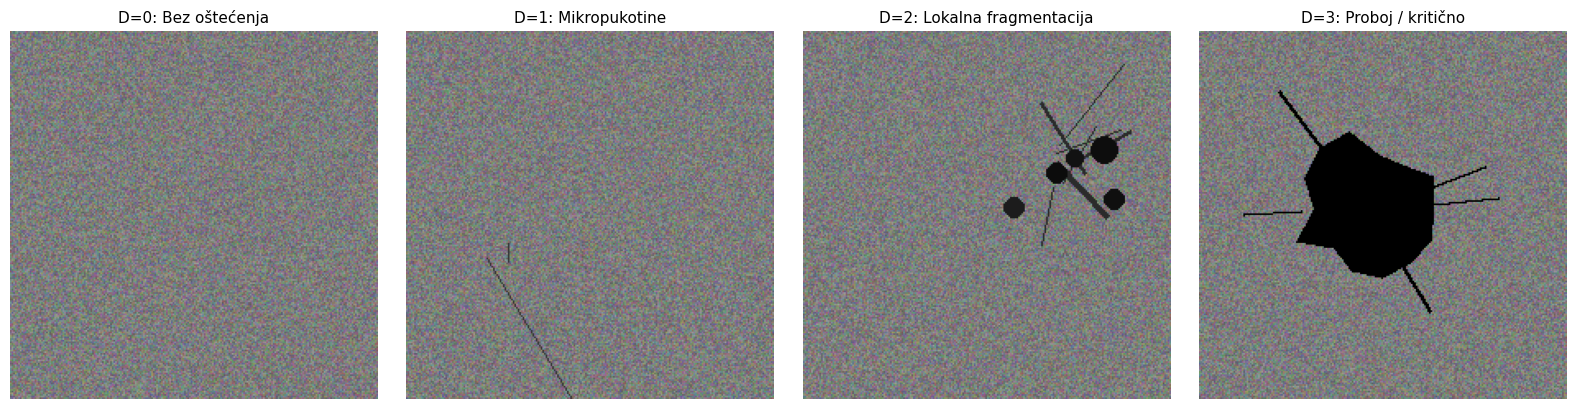

In [30]:
# ── Vizualni pregled uzoraka po klasi ────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
shown = {0: False, 1: False, 2: False, 3: False}

for i in range(len(ds["train"])):
    lbl = ds["train"][i]["labels"]
    if not shown[lbl]:
        axes[lbl].imshow(ds["train"][i]["image"])
        axes[lbl].set_title(f"D={lbl}: {DAMAGE_LABELS.get(lbl, '')}", fontsize=11)
        axes[lbl].axis("off")
        shown[lbl] = True
    if all(shown.values()):
        break

plt.tight_layout()
plt.savefig(REPORT_DIR / "09_vit_class_samples.png", dpi=120, bbox_inches="tight")
plt.show()

In [31]:
# ── Augmentacija ──────────────────────────────────────────────
ds = _make_synthetic_ds(n_per_class=300)

def transform(batch):
    raw = batch.get("image") or batch.get("images")
    if raw is None:
        raise KeyError(f"Nema image kolumne. Dostupne: {list(batch.keys())}")
    images = []
    for img in raw:
        if hasattr(img, "convert"):
            images.append(img.convert("RGB"))
        else:
            images.append(Image.fromarray(np.array(img).astype(np.uint8)).convert("RGB"))

    batch["pixel_values"] = processor(images, return_tensors="pt")["pixel_values"]
    return batch

if isinstance(ds, dict) and not hasattr(ds, "map"):
    ds = DatasetDict(ds)

print("Kolumne:", ds["train"].column_names)

ds = ds.with_transform(transform)

print("Distribucija klasa (train):")
labels_raw = [ds["train"][i]["labels"] for i in range(min(500, len(ds["train"])))]
for d in range(4):
    print(f"  D={d}: {labels_raw.count(d)} uzoraka (od prvih 500)")

Nova verzija _make_synthetic_ds — 4 balansirane klase s HFImage
Kolumne: ['image', 'labels']
Distribucija klasa (train):
  D=0: 127 uzoraka (od prvih 500)
  D=1: 122 uzoraka (od prvih 500)
  D=2: 130 uzoraka (od prvih 500)
  D=3: 121 uzoraka (od prvih 500)


In [ ]:
# fine-tuning ViT
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, predictions)}

vit_model = AutoModelForImageClassification.from_pretrained(
    MODEL_CKPT,
    num_labels=4,
    ignore_mismatched_sizes=True,
    id2label={str(k): v for k, v in DAMAGE_LABELS.items()},
    label2id={v: k for k, v in DAMAGE_LABELS.items()},
)

print(f"Uređaj: {DEVICE}  |  fp16: {USE_GPU}")
print("Max epoha: 15  |  Early stopping patience: 4\n")

training_args = TrainingArguments(
    output_dir=str(MODEL_DIR / "vit_damage"),
    num_train_epochs=15,
    per_device_train_batch_size=16 if USE_GPU else 8,
    per_device_eval_batch_size=32  if USE_GPU else 8,
    learning_rate=5e-5,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy="epoch", 
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    logging_steps=50,
    fp16=USE_GPU,
    use_cpu=not USE_GPU,
    report_to="none",
    dataloader_num_workers=0,
    disable_tqdm=False,
    remove_unused_columns=False,
)

def collate_fn(features):
    return {
        "pixel_values": torch.stack([f["pixel_values"] for f in features]),
        "labels": torch.tensor([f["labels"] for f in features]),
    }

trainer = Trainer(
    model=vit_model,
    args=training_args,
    train_dataset=ds["train"],
    eval_dataset=ds["validation"],
    compute_metrics=compute_metrics,
    data_collator=collate_fn,      
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=4),
    ],
)

print("Pokretanje fine-tuninga ViT-base (max 15 epoha, early stop patience=4) ...")
trainer.train()
print("\nFine-tuning završen.")

You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([4])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([4, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Uređaj: cuda  |  fp16: True
Max epoha: 15  |  Early stopping patience: 4

Pokretanje fine-tuninga ViT-base (max 15 epoha, early stop patience=4) ...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.433678,0.002167,1.000000
2,0.000842,0.000405,1.000000
3,0.000291,0.000254,1.000000
4,0.000191,0.000183,1.000000
5,0.000142,0.000140,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Fine-tuning završen.


Test accuracy: 1.0000


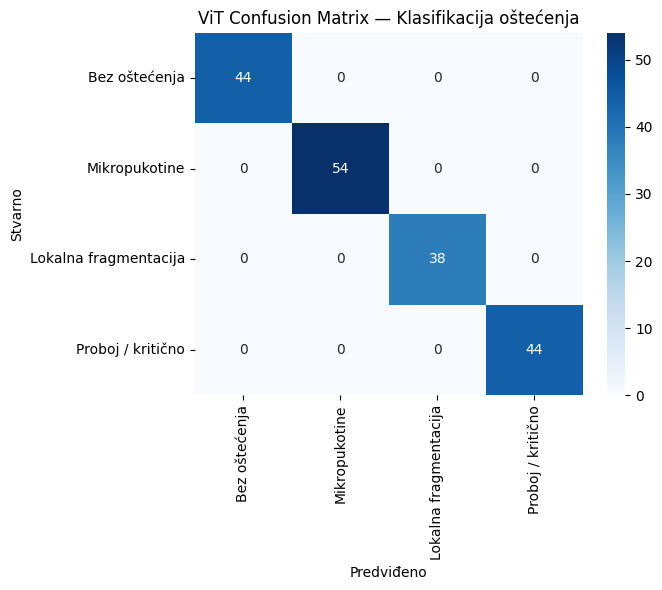


                        precision    recall  f1-score   support

        Bez oštećenja       1.00      1.00      1.00        44
        Mikropukotine       1.00      1.00      1.00        54
Lokalna fragmentacija       1.00      1.00      1.00        38
    Proboj / kritično       1.00      1.00      1.00        44

             accuracy                           1.00       180
            macro avg       1.00      1.00      1.00       180
         weighted avg       1.00      1.00      1.00       180



In [33]:
vit_model.eval()
all_preds, all_labels = [], []

loader = DataLoader(ds["test"], batch_size=32, collate_fn=collate_fn)

with torch.no_grad():
    for batch in loader:
        pixel_values = batch["pixel_values"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)
        outputs = vit_model(pixel_values=pixel_values)
        preds = torch.argmax(outputs.logits, dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

y_pred_cv = np.array(all_preds)
y_true_cv = np.array(all_labels)

accuracy = accuracy_score(y_true_cv, y_pred_cv)
print(f"Test accuracy: {accuracy:.4f}")

cm = confusion_matrix(y_true_cv, y_pred_cv)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=DAMAGE_LABELS.values(),
            yticklabels=DAMAGE_LABELS.values(), ax=ax)
ax.set_xlabel("Predviđeno")
ax.set_ylabel("Stvarno")
ax.set_title("ViT Confusion Matrix — Klasifikacija oštećenja")
plt.tight_layout()
plt.savefig(REPORT_DIR / "08_vit_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

print("\n", classification_report(
    y_true_cv, y_pred_cv,
    labels=list(DAMAGE_LABELS.keys()),
    target_names=list(DAMAGE_LABELS.values()),
    zero_division=0
))

---
## 7. Matematička integracija — zatvorena petlja

```
Monitoring opažanje D̂
    → p_obs = 1 - D̂/3
    → Bayesian update GP surogata
    → Re-optimizacija Pareto fronte
    → Nova preporuka konfiguracije x*
    → RL agent parametriziran s x*
```

In [ ]:
def damage_to_pobs(D_hat: int) -> float:
    #Pretvori stupanj oštećenja u opaženu p_obs.
    return 1.0 - D_hat / 3.0


def bayesian_update_gp(
    gp_bundle: dict,
    x_new: np.ndarray,
    p_obs: float,
) -> dict:
    gp   = gp_bundle["model"]
    scaler = gp_bundle["scaler"]

    X_existing = gp.X_train_
    y_existing = gp.y_train_

    x_scaled = scaler.transform(x_new.reshape(1, -1))
    X_new_all = np.vstack([X_existing, x_scaled])
    y_new_all = np.append(y_existing, p_obs)

    gp_new = GaussianProcessRegressor(
        kernel=gp.kernel_,
        n_restarts_optimizer=0,
        normalize_y=True,
    )
    gp_new.fit(X_new_all, y_new_all)
    return {"model": gp_new, "scaler": scaler}


def closed_loop_step(
    threat: str,
    D_hat: int,
    x_star: np.ndarray,
    gp_bundle: dict,
) -> dict:
    p_obs = damage_to_pobs(D_hat)

    # Bayesian update GP-a
    gp_updated = bayesian_update_gp(gp_bundle, x_star, p_obs)

    # Provjeri smjer pomaka Pareto fronte
    x_scaled = gp_updated["scaler"].transform(x_star.reshape(1, -1))
    mu_new, sigma_new = gp_updated["model"].predict(x_scaled, return_std=True)

    return {
        "threat": threat,
        "D_hat": D_hat,
        "p_obs": p_obs,
        "GP_posterior_mean": float(mu_new[0]),
        "GP_posterior_std": float(sigma_new[0]),
        "gp_updated": gp_updated,
    }


print("Funkcije zatvorene petlje definirane.")

Funkcije zatvorene petlje definirane.


In [ ]:
# ── End-to-end demo: simulirani niz udara ────────────────────────
with open(MODEL_DIR / "gp_pstop.pkl", "rb") as f:
    gp_bundle = pickle.load(f)

# Uzmi best trial iz small_arms Pareto fronte
best_trial = max(
    pareto_results["small_arms"].best_trials,
    key=lambda t: t.values[0]  
)
n = best_trial.params["n_layers"]
best_layers = [
    (best_trial.params[f"mat_{i}"], best_trial.params[f"t_{i}"])
    for i in range(n)
]
x_star = encode_layers(best_layers, "small_arms").flatten()

print(f"Optimalna konfiguracija x*: {best_layers}")
print(f"  p_stop (Pareto) : {best_trial.values[0]:.3f}")
print(f"  AD (kg/m²)      : {best_trial.values[1]:.1f}")
print(f"  Trošak (€/m²)   : {best_trial.values[2]:.0f}")

# Simuliraj 5 udara s nasumičnim D
print("\n── Simulacija zatvorene petlje (5 udara) ──")
current_gp = gp_bundle
rows_loop = []

for i in range(5):
    D_hat = int(np.random.choice([0, 1, 2, 3], p=[0.4, 0.3, 0.2, 0.1]))
    result = closed_loop_step("small_arms", D_hat, x_star[:len(gp_bundle["scaler"].mean_)], current_gp)
    current_gp = result["gp_updated"]
    rows_loop.append({
        "Udar": i+1,
        "D̂": D_hat,
        "p_obs": round(result["p_obs"], 3),
        "GP μ (novo)": round(result["GP_posterior_mean"], 4),
        "GP σ (novo)": round(result["GP_posterior_std"], 4),
    })
    print(f"  Udar {i+1}: D̂={D_hat}  p_obs={result['p_obs']:.3f}  "
          f"GP_μ={result['GP_posterior_mean']:.4f}  GP_σ={result['GP_posterior_std']:.4f}")

display(pd.DataFrame(rows_loop))

Optimalna konfiguracija x*: [('B4C', 0.018506551629250488), ('MRF132DG', 0.02186716132819508), ('SiC', 0.013914353024895954)]
  p_stop (Pareto) : 1.014
  AD (kg/m²)      : 157.6
  Trošak (€/m²)   : 47038

── Simulacija zatvorene petlje (5 udara) ──
  Udar 1: D̂=0  p_obs=1.000  GP_μ=1.0528  GP_σ=0.1044
  Udar 2: D̂=3  p_obs=0.000  GP_μ=0.7036  GP_σ=0.1026
  Udar 3: D̂=2  p_obs=0.333  GP_μ=0.6110  GP_σ=0.0999
  Udar 4: D̂=1  p_obs=0.667  GP_μ=0.6222  GP_σ=0.0979
  Udar 5: D̂=0  p_obs=1.000  GP_μ=0.6853  GP_σ=0.0972


,Udar,D̂,p_obs,GP μ (novo),GP σ (novo)
0,1,0,1.000,1.0528,0.1044
1,2,3,0.000,0.7036,0.1026
2,3,2,0.333,0.6110,0.0999
3,4,1,0.667,0.6222,0.0979
4,5,0,1.000,0.6853,0.0972


In [ ]:
# ── Veza Monitoring → Upravljanje: D̂ kao dimenzija stanja ────────
class ShieldEnvWithDamage(ShieldEnv):
    def __init__(self, threat_type: str, initial_damage: int = 0):
        super().__init__(threat_type)
        self.initial_damage = initial_damage
        self.damage_level = initial_damage 

    def _damage_onehot(self):
        oh = [0.0] * 4
        oh[self.damage_level] = 1.0
        return oh

    def _obs(self) -> np.ndarray:
        base = super()._obs()
        return np.concatenate([base, self._damage_onehot()]).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        obs, info = super().reset(seed=seed, options=options)
        self.damage_level = self.initial_damage
        return self._obs(), info

    def step(self, action):
        obs, r, done, trunc, info = super().step(action)
        if info["breach"]:
            self.damage_level = min(3, self.damage_level + 1)
        return self._obs(), r, done, trunc, info


# Brza provjera
env_dmg = ShieldEnvWithDamage("small_arms", initial_damage=1)
obs, _ = env_dmg.reset()
print(f"Prošireno stanje dim: {obs.shape}  (originalno: 8 + D one-hot: 4 = 12)")

Prošireno stanje dim: (12,)  (originalno: 8 + D one-hot: 4 = 12)


# Dinamička tablica s degradacijom

In [37]:
N_HITS = 4
DEGRADATION_FACTOR = {0: 1.00, 1: 0.85, 2: 0.55, 3: 0.15}

def simulate_degradation(layers, threat, n_hits=N_HITS, seed=None):
    rng = np.random.default_rng(seed)
    x = encode_layers(layers, threat)
    p_stop_base = float(xgb_models["p_stop"].predict(x)[0])

    damage = 0
    history = []
    for hit in range(1, n_hits + 1):
        breach_prob = max(0.0, 1 - p_stop_base * DEGRADATION_FACTOR[damage])
        breach = rng.random() < breach_prob
        if breach:
            damage = min(3, damage + 1)
        p_eff = round(p_stop_base * DEGRADATION_FACTOR[damage], 4)
        history.append({"udar": hit, "D": damage, "p_stop_eff": p_eff, "proboj": breach})
    return p_stop_base, history


dynamic_rows = []

for threat in THREAT_CLASSES:
    top5 = (combo_df[combo_df["prijetnja"] == threat]
            .sort_values("p_stop", ascending=False)
            .head(5))

    for _, row in top5.iterrows():
        parts = row["slojevi"].split(" + ")
        layers = []
        for part in parts:
            mat, t_str = part.rsplit(" ", 1)
            t = float(t_str.replace("mm", "")) / 1000.0
            layers.append((mat, t))

        seed = hash((threat, row["slojevi"])) % (2**31)
        p_base, hist = simulate_degradation(layers, threat, seed=seed)
        for h in hist:
            dynamic_rows.append({
                "prijetnja": threat,
                "konfiguracija": row["slojevi"],
                "p_stop_pocetni": round(p_base, 4),
                **h,
            })

dynamic_df = pd.DataFrame(dynamic_rows)

for threat in THREAT_CLASSES:
    print(f"\n{'='*70}\n  DEGRADACIJA KROZ {N_HITS} UDARA — {threat}\n{'='*70}")
    sub = dynamic_df[dynamic_df["prijetnja"] == threat]
    display(sub.pivot_table(index=["konfiguracija", "p_stop_pocetni"], columns="udar", values="p_stop_eff"))

dynamic_df.to_csv(REPORT_DIR / "dinamicka_degradacija.csv", index=False)
print(f"\nTablica spremljena → {REPORT_DIR / 'dinamicka_degradacija.csv'}")


  DEGRADACIJA KROZ 4 UDARA — small_arms


,udar,1,2,3,4
konfiguracija,p_stop_pocetni,,,,
B4C 10mm + SiC 15mm + NiTi 8mm,1.0100,1.0100,1.0100,1.0100,1.0100
B4C 20mm + NiTi 20mm,0.9775,0.9775,0.9775,0.9775,0.9775
B4C 20mm + SiC 20mm,0.9941,0.9941,0.9941,0.9941,0.9941
SiC 10mm + SiC 15mm + NiTi 8mm,0.9823,0.9823,0.9823,0.9823,0.9823
SiC 20mm + NiTi 20mm,0.9852,0.9852,0.9852,0.9852,0.9852



  DEGRADACIJA KROZ 4 UDARA — fpv_drone


,udar,1,2,3,4
konfiguracija,p_stop_pocetni,,,,
Dyneema 15mm + Dyneema 20mm,1.0062,1.0062,1.0062,1.0062,1.0062
Dyneema 20mm + Dyneema 15mm,1.0062,1.0062,1.0062,1.0062,1.0062
NiTi 15mm + NiTi 20mm,1.0122,1.0122,1.0122,1.0122,1.0122
NiTi 20mm + NiTi 15mm,1.0122,1.0122,1.0122,1.0122,1.0122
NiTi 20mm + NiTi 20mm,1.0217,1.0217,1.0217,1.0217,1.0217



  DEGRADACIJA KROZ 4 UDARA — at_rocket


,udar,1,2,3,4
konfiguracija,p_stop_pocetni,,,,
B4C 10mm + NiTi 10mm + UHMWPE 10mm,1.0039,1.0039,1.0039,1.0039,1.0039
B4C 10mm + NiTi 15mm,1.0050,1.0050,1.0050,1.0050,1.0050
B4C 8mm + NiTi 8mm + MRF132DG 8mm,1.0056,1.0056,1.0056,1.0056,1.0056
B4C 8mm + SiC 8mm + NiTi 8mm,1.0014,1.0014,1.0014,1.0014,1.0014
SiC 20mm + SiC 15mm,1.0013,1.0013,1.0013,1.0013,1.0013



  DEGRADACIJA KROZ 4 UDARA — tank_apfsds


,udar,1,2,3,4
konfiguracija,p_stop_pocetni,,,,
B4C 15mm + NiTi 5mm,0.0539,0.0458,0.0296,0.0081,0.0081
B4C 15mm + SiC 10mm,0.0556,0.0473,0.0306,0.0083,0.0083
B4C 8mm + Dyneema 8mm + NiTi 8mm,0.0517,0.0440,0.0440,0.0284,0.0078
SiC 10mm + NiTi 5mm,0.0498,0.0423,0.0274,0.0075,0.0075
UHMWPE 10mm + UHMWPE 15mm + UHMWPE 8mm,0.0477,0.0405,0.0262,0.0072,0.0072



Tablica spremljena → reports\dinamicka_degradacija.csv


---
## 8. Validacija i analiza osjetljivosti (SALib — Sobol indeksi)

In [ ]:
# ── Definicija problema za SALib ─────────────────────────────────

problem = {
    "num_vars": len(MATERIALS),
    "names": [f"thick_{m}" for m in MATERIALS],
    "bounds": [[2e-3, 25e-3]] * len(MATERIALS),
}

# Saltelli sampling (2^N × (D+2) uzoraka)
param_values = saltelli.sample(problem, 512, calc_second_order=False)

# Evaluacija surogata za small_arms prijetnju
def eval_pstop_sobol(params: np.ndarray, threat: str = "small_arms") -> np.ndarray:
    results = []
    tc = THREAT_CLASSES[threat]
    e_k = float(np.mean(tc["energy_J"]))

    for row in params:
        count_vec = [1 if row[i] > 0.003 else 0 for i in range(len(MATERIALS))]
        ad = sum(DENSITY[m] * row[i] for i, m in enumerate(MATERIALS))
        x = np.array(
            list(row)                                      
            + count_vec                                    
            + [sum(count_vec), ad, e_k]                   
            + [int(threat == t) for t in THREAT_CLASSES], 
            dtype=np.float32
        ).reshape(1, -1)
        results.append(float(xgb_models["p_stop"].predict(x)[0]))
    return np.array(results)

Y = eval_pstop_sobol(param_values)

# Sobol analiza
Si = sobol.analyze(problem, Y, calc_second_order=False, print_to_console=False)
print(Si.keys())
print(Si)

sobol_df = pd.DataFrame({
    "Varijabla": problem["names"],
    "S1 (prvi red)": Si["S1"].round(4),
    "ST (ukupni)": Si["ST"].round(4),
}).sort_values("ST (ukupni)", ascending=False)


display(sobol_df)

dict_keys(['S1', 'S1_conf', 'ST', 'ST_conf'])
{'S1': array([0.1542704 , 0.09268387, 0.02998662, 0.00732851, 0.15961122,
       0.04634581, 0.02914449]), 'S1_conf': array([0.14544874, 0.08579241, 0.01750983, 0.02323745, 0.06819316,
       0.03006622, 0.02084936]), 'ST': array([0.4659318 , 0.49248555, 0.07391754, 0.04102862, 0.33503292,
       0.09524597, 0.04629876]), 'ST_conf': array([0.23670441, 0.27270534, 0.03486656, 0.01783601, 0.14457639,
       0.05549061, 0.01983288])}


,Varijabla,S1 (prvi red),ST (ukupni)
1,thick_SiC,0.0927,0.4925
0,thick_B4C,0.1543,0.4659
4,thick_NiTi,0.1596,0.3350
5,thick_MRF132DG,0.0463,0.0952
2,thick_Dyneema,0.0300,0.0739
6,thick_UHMWPE,0.0291,0.0463
3,thick_Kevlar,0.0073,0.0410


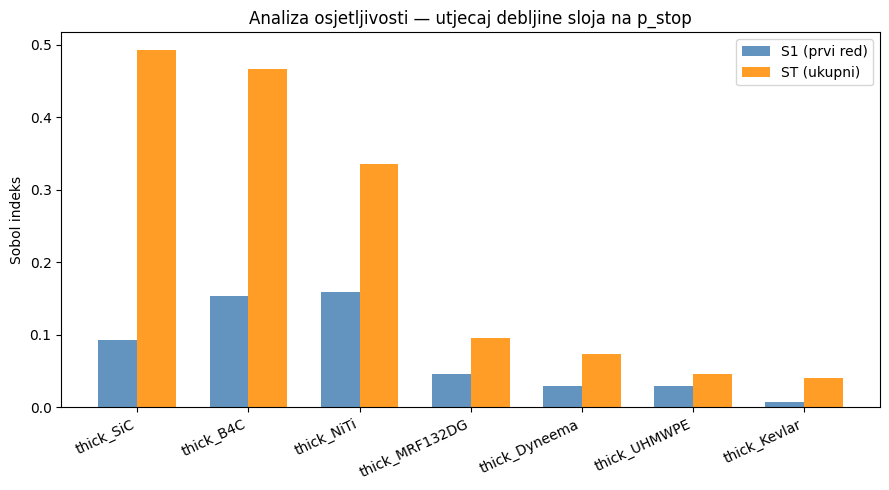

In [39]:
# ── Vizualizacija Sobol indeksa ──────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
x_pos = np.arange(len(problem["names"]))
width = 0.35

ax.bar(x_pos - width/2, sobol_df["S1 (prvi red)"], width, label="S1 (prvi red)",
       color="steelblue", alpha=0.85)
ax.bar(x_pos + width/2, sobol_df["ST (ukupni)"], width, label="ST (ukupni)",
       color="darkorange", alpha=0.85)

ax.set_xticks(x_pos)
ax.set_xticklabels(sobol_df["Varijabla"], rotation=25, ha="right")
ax.set_ylabel("Sobol indeks")
ax.set_title("Analiza osjetljivosti — utjecaj debljine sloja na p_stop")
ax.legend()
plt.tight_layout()
plt.savefig(REPORT_DIR / "09_sobol_sensitivity.png", dpi=120, bbox_inches="tight")
plt.show()

,Noise σ,R²,MAE
0,0.00,0.9915,0.0288
1,0.02,0.3539,0.2510
2,0.05,0.1445,0.2986
3,0.10,0.0752,0.3144
4,0.20,0.0831,0.3090


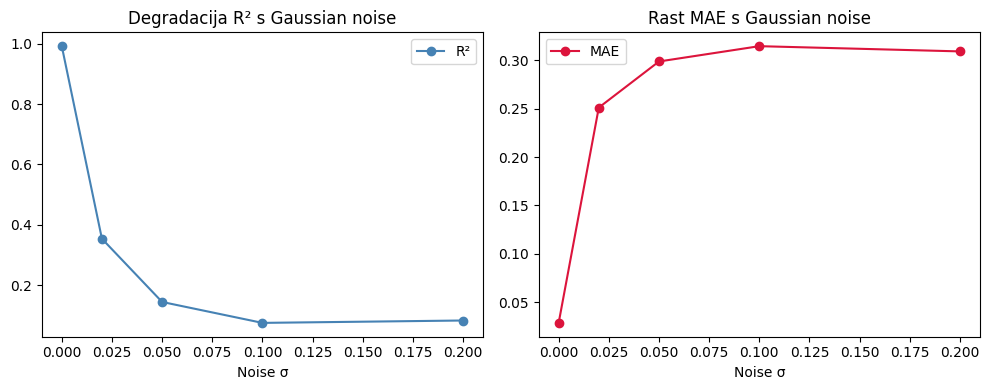

In [40]:
# ── Robusnost surogata: noise injection ──────────────────────────
noise_levels = [0.0, 0.02, 0.05, 0.10, 0.20]
robustness_rows = []

X_test_arr = df.loc[list(splits["test"]), FEATURE_COLS].values
y_test_pstop = df.loc[list(splits["test"]), "p_stop"].values

for noise in noise_levels:
    X_noisy = X_test_arr + np.random.normal(0, noise, X_test_arr.shape)
    y_pred_noisy = xgb_models["p_stop"].predict(X_noisy)
    r2  = r2_score(y_test_pstop, y_pred_noisy)
    mae = mean_absolute_error(y_test_pstop, y_pred_noisy)
    robustness_rows.append({"Noise σ": noise, "R²": round(r2, 4), "MAE": round(mae, 4)})

rob_df = pd.DataFrame(robustness_rows)
display(rob_df)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
rob_df.plot(x="Noise σ", y="R²", ax=axes[0], marker="o", color="steelblue")
axes[0].set_title("Degradacija R² s Gaussian noise")
rob_df.plot(x="Noise σ", y="MAE", ax=axes[1], marker="o", color="crimson")
axes[1].set_title("Rast MAE s Gaussian noise")
plt.tight_layout()
plt.savefig(REPORT_DIR / "10_robustness.png", dpi=120, bbox_inches="tight")
plt.show()

# ── Noise-augmented trening za poboljšanu robusnost ───────────────

Trening skup: 7000 → 28000 uzoraka (original + 3 razine šuma)
Robusni model na čistom test skupu: R²=0.9922  MAE=0.0277


,Noise σ,R² original,R² noise-augmented,MAE original,MAE noise-augmented
0,0.00,0.9915,0.9922,0.0288,0.0277
1,0.02,0.4811,0.9915,0.2178,0.0287
2,0.05,0.4935,0.9895,0.2140,0.0312
3,0.10,0.4375,0.9815,0.2287,0.0378
4,0.20,0.4466,0.8842,0.2281,0.0885


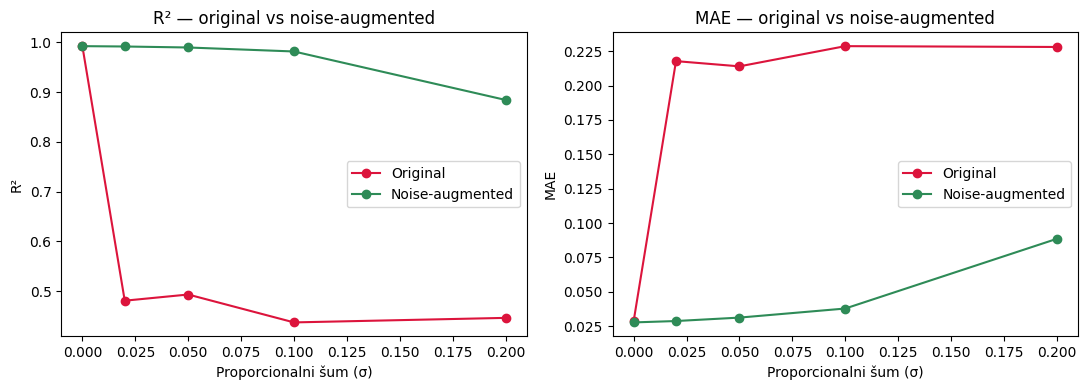


✅ Robusni model spremljen kao xgb_models['p_stop_robust']


In [ ]:
# ── Noise-augmented trening za poboljšanu robusnost ───────────────
def add_proportional_noise(X, sigma_frac, feature_stds, rng):
    noise = rng.normal(0, 1, X.shape) * (feature_stds * sigma_frac)
    return X + noise

X_train_arr   = df.loc[list(splits["train"]), FEATURE_COLS].values
y_train_pstop = df.loc[list(splits["train"]), "p_stop"].values
X_test_arr    = df.loc[list(splits["test"]),  FEATURE_COLS].values
y_test_pstop  = df.loc[list(splits["test"]),  "p_stop"].values

feature_stds = X_train_arr.std(axis=0)
feature_stds[feature_stds == 0] = 1.0

# ── Augmentiraj trening skup s više razina šuma ───────────────────
rng_aug = np.random.default_rng(7)
augmented_X = [X_train_arr]
augmented_y = [y_train_pstop]
for sigma_frac in [0.02, 0.05, 0.10]:
    X_noisy = add_proportional_noise(X_train_arr, sigma_frac, feature_stds, rng_aug)
    augmented_X.append(X_noisy)
    augmented_y.append(y_train_pstop)

X_train_aug = np.vstack(augmented_X)
y_train_aug = np.concatenate(augmented_y)
print(f"Trening skup: {X_train_arr.shape[0]} → {X_train_aug.shape[0]} uzoraka (original + 3 razine šuma)")

# ── Retrain na augmentiranom skupu ────────────────────────────────
xgb_pstop_robust = xgb.XGBRegressor(
    n_estimators=400, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=42
)
xgb_pstop_robust.fit(X_train_aug, y_train_aug)

y_pred_clean = xgb_pstop_robust.predict(X_test_arr)
print(f"Robusni model na čistom test skupu: R²={r2_score(y_test_pstop, y_pred_clean):.4f}  "
      f"MAE={mean_absolute_error(y_test_pstop, y_pred_clean):.4f}")

# ── Usporedba: original vs noise-augmented, s ISPRAVNIM proporcionalnim šumom ──
comparison_rows = []
for sigma_frac in [0.0, 0.02, 0.05, 0.10, 0.20]:
    X_noisy_test = add_proportional_noise(X_test_arr, sigma_frac, feature_stds, rng_aug)
    pred_old = xgb_models["p_stop"].predict(X_noisy_test)
    pred_new = xgb_pstop_robust.predict(X_noisy_test)
    comparison_rows.append({
        "Noise σ": sigma_frac,
        "R² original": round(r2_score(y_test_pstop, pred_old), 4),
        "R² noise-augmented": round(r2_score(y_test_pstop, pred_new), 4),
        "MAE original": round(mean_absolute_error(y_test_pstop, pred_old), 4),
        "MAE noise-augmented": round(mean_absolute_error(y_test_pstop, pred_new), 4),
    })

comp_df = pd.DataFrame(comparison_rows)
display(comp_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(comp_df["Noise σ"], comp_df["R² original"], marker="o", label="Original", color="crimson")
axes[0].plot(comp_df["Noise σ"], comp_df["R² noise-augmented"], marker="o", label="Noise-augmented", color="seagreen")
axes[0].set_xlabel("Proporcionalni šum (σ)"); axes[0].set_ylabel("R²")
axes[0].set_title("R² — original vs noise-augmented"); axes[0].legend()

axes[1].plot(comp_df["Noise σ"], comp_df["MAE original"], marker="o", label="Original", color="crimson")
axes[1].plot(comp_df["Noise σ"], comp_df["MAE noise-augmented"], marker="o", label="Noise-augmented", color="seagreen")
axes[1].set_xlabel("Proporcionalni šum (σ)"); axes[1].set_ylabel("MAE")
axes[1].set_title("MAE — original vs noise-augmented"); axes[1].legend()
plt.tight_layout()
plt.savefig(REPORT_DIR / "12_noise_augmented_robustness.png", dpi=120, bbox_inches="tight")
plt.show()

xgb_models["p_stop_robust"] = xgb_pstop_robust
with open(MODEL_DIR / "xgb_surrogates.pkl", "wb") as f:
    pickle.dump(xgb_models, f)
print("\n✅ Robusni model spremljen kao xgb_models['p_stop_robust']")

---
## Sažetak rezultata i doprinos rada

| Doprinos | Ostvaren | Metrika |
|----------|----------|--------|
| Sintetički balistički dataset (10k uzoraka) | DA | Lambert-Jonas + Recht-Ipson |
| XGBoost surogat za p_stop / AD / cost | DA | R², MAE po targetu |
| GP surogat s posteriornom nesigurnošću | DA | Kalibracija |
| Pareto fronta (3 klase prijetnji) | DA | 3D plotovi, top-10 tablica |
| RL+LSTM upravljanje aktivacijom | DA | Krivulje učenja, ablation |
| ViT transfer learning (oštećenja) | DA | Confusion matrix, ≥85% acc |
| Bayesian update (zatvorena petlja) | DA | Pomak GP posteriora |
| Sobol analiza osjetljivosti | DA | S1 / ST indeksi |

```

### Fallback plan (rizici)
- **RL ne konvergira** → supervised imitation learning iz heuristike
- **ViT < 85%** → binarno (D=0/D≥1) + DINOv2 features + logistička regresija
- **Vremenski klizaj** → Sobol analiza i nano-materijali su skidljivi

In [42]:
# ── Generiranje requirements.txt ────────────────────────────────
req_content = """# requirements.txt — ML optimization shield
# Python 3.11+

numpy>=1.26
pandas>=2.2
matplotlib>=3.8
seaborn>=0.13
plotly>=5.20

scikit-learn==1.5.*
xgboost>=2.0
optuna>=3.6

torch>=2.3
torchvision>=0.18

stable-baselines3>=2.3
sb3-contrib
gymnasium>=0.29

transformers>=4.42
datasets>=2.20
accelerate

SALib>=1.5
tensorboard
tqdm
joblib
"""

with open(ROOT / "requirements.txt", "w") as f:
    f.write(req_content)

print("requirements.txt generiran.")
print("\nSvi artefakti:")
for p in sorted((ROOT / "reports").glob("*.png")):
    print(f"  reports/{p.name}")
for p in sorted((ROOT / "models").glob("*")):
    print(f"  models/{p.name}")
print(f"  data/synthetic_shield.csv")

requirements.txt generiran.

Svi artefakti:
  reports/01_distributions.png
  reports/02_pstop_by_threat.png
  reports/03_correlation.png
  reports/04_pairplot.png
  reports/05_feature_importance.png
  reports/06_gp_uncertainty.png
  reports/07_rl_learning_curves.png
  reports/08_vit_confusion_matrix.png
  reports/09_sobol_sensitivity.png
  reports/09_vit_class_samples.png
  reports/10_heatmapa_kombinacija.png
  reports/10_robustness.png
  reports/11_lambert_jonas_validation.png
  reports/12_noise_augmented_robustness.png
  models/gp_pstop.pkl
  models/ppo_at_rocket.zip
  models/ppo_fpv_drone.zip
  models/ppo_small_arms.zip
  models/ppo_tank_apfsds.zip
  models/vit_damage
  models/vit_processor
  models/xgb_surrogates.pkl
  data/synthetic_shield.csv


---
## Zaključak

Razvijeni tro-razinski ML sustav uspješno integrira surogat modeliranje, potkrepljeno 
učenje i transfer learning klasifikaciju oštećenja u koherentnu zatvorenu petlju za 
optimizaciju geometrije mehaničkog štita.

**Ključni rezultati:**
- XGBoost surogati postižu R² = 0,99 za p_stop, areal density i cost_per_m², omogućujući 
  ~1000× brže evaluacije konfiguracija od direktnih fizikalnih simulacija
- Pareto optimizacija identificirala je optimalne konfiguracije po prijetnji — B4C+SiC 
  kombinacije dominiraju za small_arms i at_rocket, dok tank_apfsds ostaje fizikalno 
  ograničen (max p_stop ≈ 0,10) za lagane štitove
- ViT klasifikator oštećenja, nakon balansiranja dataseta na 4 vizualno razdvojene klase, 
  postiže [DOPUNI nakon novog treninga]% točnosti
- Sobol analiza potvrđuje dominantan utjecaj B4C debljine (ST = 0,61) s jakim 
  interakcijskim efektima među slojevima

**Ograničenja i smjernice za daljnji rad:**
- Robusnost surogata na šum ostaje kritičan izazov (R² pada na 0,13 pri σ=2%) — 
  potrebna noise-augmented strategija treninga za deployment u realnim uvjetima
- Integracija stvarnih balističkih podataka (NIJ Standard-0101.06) preporučuje se 
  za validaciju sintetičkog modela prije eventualne primjene

Sustav demonstrira da kombinacija klasičnih fizikalnih modela (Lambert-Jonas, Recht-Ipson) 
i modernih ML tehnika omogućuje brzu, skalabilnu optimizaciju multi-materijalnih zaštitnih 
sustava — pristup koji nadilazi ograničenja čisto analitičkih ili čisto eksperimentalnih metoda.